In [1]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plot
from matplotlib.font_manager import FontProperties
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
import sklearn.metrics
from sklearn.metrics import explained_variance_score, mean_squared_error, r2_score # https://scikit-learn.org/stable/auto_examples/linear_model/plot_ols.html
import statsmodels.api as sm
import pandas
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import scipy as sp
from scipy.odr import *
import scipy.stats
import random
import operator
import os
import seaborn as sns
from mpl_toolkits.mplot3d import axes3d
from matplotlib.patches import Polygon
import matplotlib.colors as mcolors
from matplotlib import cm
#from colorspacious import cspace_converter
from matplotlib.pyplot import figure

# For 3d plots. This import is necessary to have 3D plotting below
from mpl_toolkits.mplot3d import Axes3D

# For statistics. Requires statsmodels 5.0 or more
from statsmodels.formula.api import ols
from statsmodels.formula.api import wls
# Analysis of Variance (ANOVA) on linear models
from statsmodels.stats.anova import anova_lm

# Adapted from:
# https://www.datasciencecentral.com/profiles/blogs/linear-regression-in-python-use-of-numpy-scipy-and-statsmodels,
# https://realpython.com/linear-regression-in-python/#multiple-linear-regression

In [2]:
plt.rcParams['figure.facecolor'] = 'w'
plt.rcParams['figure.edgecolor'] = 'w'

In [3]:
M0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundMStarData.csv',delimiter=',',skip_header=0))) # No header, so don't skip
M1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneMStarData.csv',delimiter=',',skip_header=0))) # Has header, so skip
C0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundamentalCStarData.csv',delimiter=',',skip_header=0))) # Has header, so skip
C1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneCStarData.csv',delimiter=',',skip_header=0))) # No header, so don't skip

print(np.shape(M0StarData))
print(np.shape(M1StarData))
print(np.shape(C0StarData))
print(np.shape(C1StarData))




MdotIndex=5 # Column of imported files that has Mdot data
MdotErrorIndex=6 # Absolute error in Mdot
MdotDustIndex=2 # Column of imported files that has Mdot_dust Data
LIndex=8 # Column of imported files that has LBol data
LErrorIndex=9 # Absolute error in L
PIndex=13 # Column of imported files that has Period data
JIndex=14 # Column of imported files that has J-band magnitude
HIndex=15 # Column of imported files that has J-band magnitude
KIndex=16 # Column of imported files that has J-band magnitude
ThreePointSixIndex=17 # Column of imported files that has 3.6 band magnitude
FourPointFiveIndex=18 # Column of imported files that has 3.6 band magnitude
FivePointEightIndex=19 # Column of imported files that has 3.6 band magnitude
EightPointZeroIndex=20 # Column of imported files that has 8.0 band magnitude
MIndex=22 # Column of imported files that has Mass data
RIndex=23 # Column of imported files that has Radius data
TeffObsvIndex=12 # Column of imported files that has Observed Teff Data
TeffCalcIndex=24 # Column of imported files that has Calculated Teff Data
tauIndex=27 # Column of imported files that has Optical Depth data
AmpIndex=28 # Column of imported files that has pulsation amplitude data

(29, 1979)
(29, 2162)
(29, 1994)
(29, 781)


In [4]:
def van_Loon_psi_for_non_solar (spec_type, solar_ratio, input_z):
    # Take spectral type (M or C), the solar ratio (dust-to-gas ratio for sun-like metallicity), intial metallicity z (divided by solar) for target, to find
    # dust-to-gas ratio for target metallicity
    if spec_type == 'M':
        # First, use the solar ratio to determine the constant in formula. Zsun ~ 0.0124
        constant = np.log10(solar_ratio) - 0.7*np.log10(0.0124/0.0124)
        constant_lower = np.log10(solar_ratio) - (0.7 - 0.3)*np.log10(0.0124/0.0124)
        constant_upper = np.log10(solar_ratio) - (0.7 + 0.6)*np.log10(0.0124/0.0124)
        dtg_ratio = 10**(0.7*np.log10(input_z)+constant)
        dtg_ratio_lower = 10**((0.7- 0.3)*np.log10(input_z)+constant_lower)
        dtg_ratio_upper = 10**((0.7+ 0.6)*np.log10(input_z)+constant_upper)
    elif spec_type == 'C':
        constant = np.log10(solar_ratio) - 1*np.log10(0.0124/0.0124)
        constant_lower = np.log10(solar_ratio) - (1 - 0.3)*np.log10(0.0124/0.0124)
        constant_upper = np.log10(solar_ratio) - (1 + 0.3)*np.log10(0.0124/0.0124)
        dtg_ratio = 10**(1*np.log10(input_z)+constant)
        dtg_ratio_lower = 10**((1- 0.3)*np.log10(input_z)+constant_lower)
        dtg_ratio_upper = 10**((1+ 0.3)*np.log10(input_z)+constant_upper)
    else:
        print('Error. Invalid Spectral Type.')
    return np.asarray([dtg_ratio_lower, dtg_ratio, dtg_ratio_upper])

ratios_M = (van_Loon_psi_for_non_solar('M',1/500,0.001/0.0124))**-1
ratios_C = (van_Loon_psi_for_non_solar('C',1/200,0.001/0.0124))**-1

In [5]:
def correct_mdot (star_data,multiplier):
    new_mdot_data = multiplier*star_data[MdotDustIndex]
    new_mdot_error_data = multiplier*star_data[MdotDustIndex+1]
    new_star_data_array = []
    for i in range(0, len(star_data)):
        new_star_data_array.append(star_data[i])
    new_star_data_array = np.asarray(new_star_data_array)
    print(star_data[MdotIndex])
    new_star_data_array[MdotIndex] = new_mdot_data
    print(new_star_data_array[MdotIndex])
    new_star_data_array[MdotErrorIndex] = new_mdot_error_data
    return new_star_data_array

M0StarData = correct_mdot (M0StarData, int(ratios_M[1]))
M1StarData = correct_mdot (M1StarData, int(ratios_M[1]))
C0StarData = correct_mdot (C0StarData, int(ratios_C[1]))
C1StarData = correct_mdot (C1StarData, int(ratios_C[1]))

[2.82321670e-07 1.17163493e-07 3.24669921e-07 ... 2.82321670e-07
 2.54089503e-07 5.92875508e-08]
[5.82600e-07 2.41779e-07 6.69990e-07 ... 5.82600e-07 5.24340e-07
 1.22346e-07]
[4.23482506e-07 5.22295090e-08 1.03047410e-07 ... 3.52902088e-08
 2.25857336e-07 3.95250339e-08]
[8.73900e-07 1.07781e-07 2.12649e-07 ... 7.28250e-08 4.66080e-07
 8.15640e-08]
[1.81458349e-07 1.81458349e-07 3.67237135e-06 ... 6.26463347e-06
 8.20883007e-07 9.07291744e-08]
[2.0832e-07 2.0832e-07 4.2160e-06 ... 7.1920e-06 9.4240e-07 1.0416e-07]
[8.20883007e-08 5.40054610e-08 2.37624028e-07 2.05220752e-06
 3.45634950e-08 2.05220752e-06 8.42485191e-08 1.03690485e-06
 3.67237135e-08 1.44734635e-07 9.28893929e-08 1.18812014e-06
 5.40054610e-08 1.14491577e-07 1.81458349e-07 3.67237135e-08
 3.67237135e-08 4.53645872e-08 8.42485191e-08 2.80828397e-07
 7.34474269e-08 1.29613106e-07 2.37624028e-07 5.40054610e-07
 9.07291744e-08 1.03690485e-06 1.14491577e-07 1.36093762e-07
 7.34474269e-08 6.48065532e-08 2.37624028e-07 3.8883

In [6]:
# First, define function for ODR
def linear_fit_1var (xdata, ydata):
    x = xdata
    y = ydata
    
    data = pandas.DataFrame({'x': x, 'y': y})
    model = ols("y ~ x", data).fit()
    # Parameters are returned in the format intercept, slope
    return model._results.params, model._results.rsquared, model.bse, model.normalized_cov_params
def multilinear_fit_2var (xdata, ydata):
    x0 = xdata[0]
    x1 = xdata[1]
    y = ydata
    
    data = pandas.DataFrame({'x0': x0, 'x1': x1, 'y': y})
    model = ols("y ~ x0 + x1", data).fit()
    
    # Parameters are returned in the format intercept, slope 1, slope 2
    return model._results.params, model._results.rsquared, model.bse, model.normalized_cov_params
def f10(B, x):
    '''Multi-Linear function y = B[0]*x0 + B[1]*x[1] + B[2]'''
    # B is a vector of the parameters.
    # x is an array of the current x values.
    # x is in the same format as the x passed to Data or RealData.
    #
    # Return an array in the same format as y passed to Data or RealData.
    return B[0]*x + B[1]
def do_odr_fit (data_to_fit):
    linear = Model(f10)
    logMdotData = np.log10(data_to_fit[5])
    logPData = np.log10(data_to_fit[13])
    logLData = np.log10(data_to_fit[8])
    mydata = Data(logPData,logMdotData)
    myodr = ODR(mydata,linear,beta0=[1,1,1])
    myrun = myodr.run()
    myrun.pprint()
    return myrun.beta # Return the information we need to create the fitting function and plot it

def chi_sq_fit_2d (data_x, data_y, print_model_results = 0):
    # First, let's look at all of the Fundamental mode data at once.
    # Convert the data into a Pandas DataFrame to use the formulas framework
    # in statsmodels

    # First we need to flatten the data: it's 2D layout is not relevent.
    x = data_x
    y = data_y

    data = pandas.DataFrame({'x': data_x, 'y': data_y})

    # Fit the model
    model = ols("y ~ x ", data).fit()

    # Print the summary
    if print_model_results != 0:
        print(model.summary())

        print("\nRetrieving manually the parameter estimates:")
        print(model._results.params)

        print("\nRetrieving manually the R^2 value:")
        print(model._results.rsquared)
        # Peform analysis of variance on fitted linear model
        anova_results = anova_lm(model)
        print('\nANOVA results')
        print(anova_results)
        
    parameters = model._results.params
    rsquared = model._results.rsquared
    return parameters, rsquared


def multilinear_fit_2var_WLS (xdata, ydata, xdata_error, ydata_error):
    std_error_x0 = np.nanstd(xdata_error)
    std_error_y = np.nanstd(ydata_error)
    x0 = xdata[0] # logL
    x1 = xdata[1] # logP
    y = ydata # logMdot
    
    wls_model = sm.WLS(ydata, xdata, [1/std_error_x0**2, 1, 1/std_error_y**2])
    
    # Parameters are returned in the format intercept, slope 1, slope 2
    return model._results.params, model._results.rsquared, model.bse

In [7]:

M0_optimal_exponents_LM_old = np.asarray([-22.0628, 8.114, -13.6909])
M1_optimal_exponents_LM_old = np.asarray([-29.647, 10.11, -20.48])
C0_optimal_exponents_LM_old = np.asarray([-27.55, 2.37, -6.65])
C1_optimal_exponents_LM_old = np.asarray([-28.1, 5.89, -9.44])

M0_optimal_exponents_LP = np.asarray([-6.628255171139944, -6.672284306164037, 10.658943164562999])
M1_optimal_exponents_LP = np.asarray([-0.2629365379324566, -13.889119919712511, 22.191369583953307])
C0_optimal_exponents_LP = np.asarray([-14.949265552653978, -3.5927613252629285, 8.77537912683285])
C1_optimal_exponents_LP = np.asarray([-10.375944771010456, -3.93959257905946, 8.493980612691866])

M0_optimal_exponents_LM = np.asarray([-35.647302549264865, 8.23563337208871, -13.73913258342892])
M1_optimal_exponents_LM = np.asarray([-43.144873380876305, 10.150790750584106, -20.48418752185978])
C0_optimal_exponents_LM = np.asarray([-40.79178301409364, 9.620248047597151, -13.899788094084272])
C1_optimal_exponents_LM = np.asarray([-27.882973151635788, 5.888707448080171, -9.440804631588628])

In [8]:
# PML coefficients can be constructed from RLM and PMR relations
# logR = AR + BRlogL + CRlogM
# logP = AP + BPlogM + CPlogR
# => logP = AP + BPlogM + CP(AR + BRlogL + CRlogM) = (AP + CP*AR) + (BP+CP*CR)logM + (CP*BR)logL = A + BlogM + C logL
RLM_M = [-0.241, 0.690, -0.251]
RLM_C = [-0.323, 0.737, -0.371]
PMR_M0 = [-2.234, -0.7802, 2.027]
PMR_M1 = [-1.554, -0.529, 1.570]
PMR_C0 = [-2.285, -0.826, 2.043]
PMR_C1 = [-1.554, -0.529, 1.570]

def calculate_PML_coeffs (RLM_coeffs, PMR_coeffs):
    A = PMR_coeffs[0] + PMR_coeffs[2]*RLM_coeffs[0]
    B = PMR_coeffs[1] + PMR_coeffs[2]*RLM_coeffs[2]
    C = PMR_coeffs[2]*RLM_coeffs[1]
    return np.asarray([A, B, C])

PML_M0 = calculate_PML_coeffs(RLM_M,PMR_M0)
PML_M1 = calculate_PML_coeffs(RLM_M,PMR_M1)
PML_C0 = calculate_PML_coeffs(RLM_C,PMR_C0)
PML_C1 = calculate_PML_coeffs(RLM_C,PMR_C1)

In [9]:
def calc_vw_mdot (log_period, log_mass):
    # log Mdot = -11.4 + 0.0125(P-100(M-2.5))
    # http://cdsads.u-strasbg.fr/pdf/1993ApJ...413..641V
    logMdot_array = []
    for i in range (0, len(log_period)):
        mass = 10**(log_mass[i])
        period = 10**(log_period[i])
        if mass > 2.5:
            # eq. 5 in above reference
            logMdot = -11.4 + 0.0125*(period - 100*(mass-2.5))
        else:
            # Eq. 2 in above reference
            logMdot = -11.4 + 0.0123*(period)
        logMdot_array.append(logMdot)
    return np.asarray(logMdot_array)

def calc_de_beck_mdot (log_period):
    # log Mdot = -7.37 + 3.42*10^-3 * P (P<850)
    #          = -4.46                  (P>850)
    logMdot_array = []
    for i in range (0, len(log_period)):
        period = 10**(log_period[i])
        if period < 850:
            logMdot = -7.37 + 3.42*10**(-3)*period
        else:
            logMdot = -4.46
        logMdot_array.append(logMdot)
    return np.asarray(logMdot_array)

In [10]:
def mdot_formula_comparison (star_data, spec_mode_label = '',marker_size=2, strip_type = "LM", save = False):
    logMData = np.log10(star_data[MIndex])
    logLData = np.log10(star_data[LIndex])
    logPData = np.log10(star_data[PIndex])
    logMdotData = np.log10(star_data[MdotIndex])
    logMdotperMData = np.log10(star_data[MdotIndex]/star_data[MIndex])
    fit_primary = multilinear_fit_2var([logLData,logPData],logMdotData)
    # Returns logMdot = A + BlogL + ClogP
    fit_secondary = multilinear_fit_2var([logMdotData,logPData],logLData)
    # Returns logL = A + BlogMdot + ClogP
    
    LPCoeffs = fit_primary[0]
    MdotPCoeffs = fit_secondary[0]
    our_log_mdot = LPCoeffs[0] + LPCoeffs[1]*logLData + LPCoeffs[2]*logPData
    attenuation_log_mdot = (logLData - MdotPCoeffs[0] - MdotPCoeffs[2]*logPData)/MdotPCoeffs[1]
    # log Mdot = A + BlogL + ClogP
    if spec_mode_label[0] == 'M':
        RLM = RLM_M
    elif spec_mode_label[0] == 'C':
        RLM = RLM_C
    else:
        print('Error. Invalid label.')
        #break
    if spec_mode_label == 'M0':
        PMR = PMR_M0
        if strip_type == "LM":
            dz_values = M0_optimal_exponents_LM
        elif strip_type == "LP":
            dz_values = M0_optimal_exponents_LP
        else:
            print('Error. No strip Type Specified.')
            #break
    elif spec_mode_label == 'M1':
        PMR = PMR_M1
        if strip_type == "LM":
            dz_values = M1_optimal_exponents_LM
        elif strip_type == "LP":
            dz_values = M1_optimal_exponents_LP
        else:
            print('Error. No strip Type Specified.')
            #break
    elif spec_mode_label == 'C0':
        PMR = PMR_C0
        if strip_type == "LM":
            dz_values = C0_optimal_exponents_LM
        elif strip_type == "LP":
            dz_values = C0_optimal_exponents_LP
        else:
            print('Error. No strip Type Specified.')
            #break
    elif spec_mode_label == 'C0x':
        PMR = PMR_C0
        if strip_type == "LM":
            dz_values = C0_optimal_exponents_LM
        elif strip_type == "LP":
            dz_values = C0_optimal_exponents_LP
        else:
            print('Error. No strip Type Specified.')
            #break
    elif spec_mode_label == 'C0 and C0x':
        PMR = PMR_C0
        if strip_type == "LM":
            dz_values = C0_optimal_exponents_LM
        elif strip_type == "LP":
            dz_values = C0_optimal_exponents_LP
        else:
            print('Error. No strip Type Specified.')
            #break
    elif spec_mode_label == 'C1':
        PMR = PMR_C1
        if strip_type == "LM":
            dz_values = C1_optimal_exponents_LM
        elif strip_type == "LP":
            dz_values = C1_optimal_exponents_LP
        else:
            print('Error. No strip Type Specified.')
            #break
    else:
        print('Error. Invalid label.')
        #break
    
    #artificial_data = make_artificial_set([star_data],0.2,grid_spacing = 75j)
    #artificial_logLData = artificial_data[0]
    #artificial_logMData = artificial_data[1]
    #artificial_logRData = RLM[0] + RLM[1]*artificial_logLData + RLM[2]*artificial_logMData
    #artificial_logPData = PMR[0] + PMR[1]*artificial_logMData + PMR[2]*artificial_logRData
    #artificial_logTData = np.log10(5778*np.sqrt(10**(artificial_logRData)/np.sqrt(10**artificial_logLData)))
        
    a = LPCoeffs[0]
    arlm = RLM[0]
    aRLM = arlm
    apmr = PMR[0]
    aPMR = apmr
    c = LPCoeffs[2]
    cpmr = PMR[2]
    cPMR = cpmr
    b = LPCoeffs[1]
    brlm = RLM[1]
    bRLM = brlm
    bpmr = PMR[1]
    bPMR = bpmr
    crlm = RLM[2]
    cRLM = crlm
    PMLCoeffs = calculate_PML_coeffs(RLM, PMR)
    aPML = PMLCoeffs[0]
    bPML = PMLCoeffs[1]
    cPML = PMLCoeffs[2]
    
    
    # Coefficients for the Mdot(L,P) fit as a function Mdot(L, P)
    aMdotLP = a
    bMdotLP   = b
    cMdotLP  = c
    
    Anew = a - arlm + apmr*c + arlm*c*cpmr
    Bnew = b - brlm + brlm*c*cpmr 
    Cnew = bpmr*c - crlm + c*cpmr*crlm
    print('log Mdot(logL, logP):')
    #print('LRM form: logMdot =',Anew,' + ',Bnew,'logL + logR -',-Cnew,'logM')
    print('LM form: logMdot =',Anew+arlm,' + ',Bnew+brlm,'logL -',-(Cnew+crlm),'logM')
    #####
    
    # Use artificial star data to create plots demonstrating how our formulas differ from eachother and other notable formulas 
    logLData = np.log10(star_data[LIndex])
    logMData = np.log10(star_data[MIndex])
    logPData = np.log10(star_data[PIndex])
    logRData = np.log10(star_data[RIndex])
    logTData = np.log10(star_data[TeffCalcIndex])
    logMdotData = np.log10(star_data[MdotIndex])
    
    
    color_list = ['tab:blue','tab:orange','tab:green','tab:red','tab:purple','tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']
    
    LPmultilinear_fit = multilinear_fit_2var([logLData,logPData],logMdotData)
    LPCoeffs = LPmultilinear_fit[0]
    our_log_mdot = LPCoeffs[0] + LPCoeffs[1]*logLData + LPCoeffs[2]*logPData
    # log Mdot = A + BlogL + ClogP
    '''
    if spec_mode_label[0] == 'M':
        RLM = RLM_M
    if spec_mode_label[0] == 'C':
        RLM = RLM_C
    if spec_mode_label == 'M0':
        PMR = PMR_M0
        dz_values = deathzone_values_M0
    if spec_mode_label == 'M1':
        PMR = PMR_M1
        dz_values = deathzone_values_M1
    if spec_mode_label == 'C0':
        PMR = PMR_C0
        dz_values = deathzone_values_C0
    if spec_mode_label == 'C0x':
        PMR = PMR_C0
        dz_values = deathzone_values_C0x
    if spec_mode_label == 'C0 and C0x':
        PMR = PMR_C0
        dz_values = deathzone_values_C0_and_C0x
    if spec_mode_label == 'C1':
        PMR = PMR_C1
        dz_values = deathzone_values_C1
    if spec_mode_label == 'C0 and C0x':
        PMR = PMR_C0
        dz_values = deathzone_values_C0_and_C0x
    '''
    
    #artificial_data = make_artificial_set([star_data],0.2,grid_spacing = 75j)
    #artificial_logLData = artificial_data[0]
    #artificial_logMData = artificial_data[1]
    #artificial_logRData = RLM[0] + RLM[1]*artificial_logLData + RLM[2]*artificial_logMData
    #artificial_logPData = PMR[0] + PMR[1]*artificial_logMData + PMR[2]*artificial_logRData
    #artificial_logTData = np.log10(5778*np.sqrt(10**(artificial_logRData)/np.sqrt(10**artificial_logLData)))
        
    a = LPCoeffs[0]
    arlm = RLM[0]
    aRLM = arlm
    apmr = PMR[0]
    aPMR = apmr
    c = LPCoeffs[2]
    cpmr = PMR[2]
    cPMR = cpmr
    b = LPCoeffs[1]
    brlm = RLM[1]
    bRLM = brlm
    bpmr = PMR[1]
    bPMR = bpmr
    crlm = RLM[2]
    cRLM = crlm
    PMLCoeffs = calculate_PML_coeffs(RLM, PMR)
    aPML = PMLCoeffs[0]
    bPML = PMLCoeffs[1]
    cPML = PMLCoeffs[2]
    
    Anew = a - arlm + apmr*c + arlm*c*cpmr
    Bnew = b - brlm + brlm*c*cpmr 
    Cnew = bpmr*c - crlm + c*cpmr*crlm
    print('log Mdot ~ logL + logP:')
    print('LRM form: logMdot =',Anew,' + ',Bnew,'logL + logR -',-Cnew,'logM')
    print('LM form: logMdot =',Anew+arlm,' + ',Bnew+brlm,'logL -',-(Cnew+crlm),'logM')
    
    print('______________')
    
    if strip_type == "LM":
        print('log Mdot ~ logL + logM (LM Strip)')
        print('LM form: logMdot =',dz_values[0],' + ',dz_values[1],'logL -',np.abs(dz_values[2]),'logM')
    if strip_type == "LP":
        print('log Mdot ~ logL + logP (LP Strip)')
        print('LP form: logMdot =',dz_values[0],' + ',dz_values[1],'logL -',np.abs(dz_values[2]),'logP')
    
    print('______________')
    
    
    Reimers_log_mdot = np.log10(4*10**-13) + logLData + logRData - logMData
    # Mdot = (4*10^-13) * eta * LR/M => logMdot = log(4*10^-13) + log(eta) + logL + logR - logM
    # 1975
    print('Reimers 1975 LRM form: logMdot =',np.log10(4*10**-13),'+ logL + logR - logM')
    Aprint = np.log10(4*10**-13) + aRLM
    Bprint = 1 + bRLM
    Cprint = -1 + cRLM
    print('Reimers 1975 LM form: logMdot =', Aprint,'+',Bprint,'logL - ',np.abs(Cprint),'logM')
    fit = linear_fit_1var(logMdotData,Reimers_log_mdot)
    print('Calc vs Obsv Slope:', fit[0][1])
    print('Calc vs Obsv R^2:',fit[1])
    print('SDev of Residual:',np.nanstd(Reimers_log_mdot-logMdotData))
    print('Mean distance from 1-to-1 line:',np.nanmean(np.abs(Reimers_log_mdot-logMdotData)))
    
    print('______________')
    
    Reimers_log_mdot_2 = Reimers_log_mdot +np.log10(0.35)
    # Mdot = (4*10^-13) * 0.35 * LR/M => logMdot = log(4*10^-13) + log(0.35) + logL + logR - logM
    # http://cdsads.u-strasbg.fr/pdf/1977A%26A....61..217R, 1977
    print('Reimers 1977 LRM form: logMdot =',np.log10(4*10**-13)+np.log10(0.35),'+ logL + logR - logM')
    Aprint = np.log10(4*10**-13)+np.log10(0.35) + aRLM
    Bprint = 1 + bRLM
    Cprint = -1 + cRLM
    print('Reimers 1977 LM form: logMdot =', Aprint,'+',Bprint,'logL - ',np.abs(Cprint),'logM')
    fit = linear_fit_1var(logMdotData,Reimers_log_mdot_2)
    print('Calc vs Obsv Slope:', fit[0][1])
    print('Calc vs Obsv R^2:',fit[1])
    print('SDev of Residual:',np.nanstd(Reimers_log_mdot_2-logMdotData))
    print('Mean distance from 1-to-1 line:',np.nanmean(np.abs(Reimers_log_mdot_2-logMdotData)))
    
    print('______________')
    
    VW_log_mdot = calc_vw_mdot(logPData, logMData)
    # log Mdot = -11.4 + 0.0125(P-100(M-2.5))
    # http://adsabs.harvard.edu/abs/1993ApJ...413..641V, 1993
    apprx_fit = multilinear_fit_2var([logLData,logMData],VW_log_mdot)
    apprx_fit_coeffs = apprx_fit[0]
    print('VW LRM form: N/A')
    if apprx_fit_coeffs[2]>0:
        print('VW LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','+',apprx_fit_coeffs[2],'logM')
    else:
        print('VW LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','-',np.abs(apprx_fit_coeffs[2]),'logM')
    fit = linear_fit_1var(logMdotData,VW_log_mdot)
    print('Calc vs Obsv Slope:', fit[0][1])
    print('Calc vs Obsv R^2:',fit[1])
    print('SDev of Residual:',np.nanstd(VW_log_mdot-logMdotData))
    print('Mean distance from 1-to-1 line:',np.nanmean(np.abs(VW_log_mdot-logMdotData)))

    print('______________')
    
    Bloecker_log_mdot = np.log10(1.932*10**-21) + 3.7*logLData + logRData - 3.1*logMData
    # Mdot = (4.83*10^-9) (M^-2.1)(L^2.7)(Mdot_R=(4*10^-13) * eta * LR/M) = (1.932*10^-21)(L^3.7)(R)(M^-3.1)
    # -> logMdot = log[1.932*10^-21] + 3.7logL + logR - 3.1logM
    # https://ui.adsabs.harvard.edu/abs/1995A&A...297..727B, 1995
    print('Bloecker LRM form: logMdot =',np.log10(1.932*10**-21),'+3.7logL + logR - 3.1logM')
    Aprint = np.log10(1.932*10**-21) + aRLM
    Bprint = 3.7 + bRLM
    Cprint = -3.1 + cRLM
    print('Bloecker LM form: logMdot =',Aprint,'+',Bprint,'logL - ',np.abs(Cprint), 'logM')
    fit = linear_fit_1var(logMdotData,Bloecker_log_mdot)
    print('Calc vs Obsv Slope:', fit[0][1])
    print('Calc vs Obsv R^2:',fit[1])
    print('SDev of Residual:',np.nanstd(Bloecker_log_mdot-logMdotData))
    print('Mean distance from 1-to-1 line:',np.nanmean(np.abs(Bloecker_log_mdot-logMdotData)))
    
    print('______________')
    
    Wachter_log_mdot = 9.84423 + 1.54*logLData - 1.95*logMData + 0.959*logPData - 6.8*logTData
    # logMdot = -4.52 - 6.81(logT/2600 K) + 1.54log(L/10^4 Lsun) - 1.95log(M/Msun)+0.959log(P/650d)
    # -> logMdot = 9.84423 + 1.54logL -1.95logM + 0.959logP - 6.8logT
    # https://ui.adsabs.harvard.edu/abs/2002A&A...384..452W, 2002
    # from definition of effective temp., logT = 0.940482 + 0.25logL - 0.5logR (in solar units and Tsun = 5780K)
    WachterA = -6.39528 + 9.84423 + 0.959*aPML + 2.4*aRLM
    WachterB = -1.7 + 1.54 + 0.959*bPML+2.4*bRLM
    WachterC = -1.95 + 0.959*cPML+2.4*cRLM
    if WachterC <0:
        print('Wachter LRM form: logMdot =',WachterA,' + ',WachterB,'logL - ',np.abs(WachterC),'logM + logR')
    else:
        print('Wachter LRM form: logMdot =',WachterA,' + ',WachterB,'logL + ',WachterC,'logM + logR')
    Aprint = WachterA + aRLM
    Bprint = WachterB + bRLM
    Cprint = WachterC + cRLM
    if Cprint < 0:
        print('Wachter LM form: logMdot =',Aprint,' + ',Bprint,'logL - ',np.abs(Cprint),'logM')
    else:
        print('Wachter LM form: logMdot =',Aprint,' + ',Bprint,'logL + ',Cprint,'logM')
    fit = linear_fit_1var(logMdotData,Wachter_log_mdot)
    print('Calc vs Obsv Slope:', fit[0][1])
    print('Calc vs Obsv R^2:',fit[1])
    print('SDev of Residual:',np.nanstd(Wachter_log_mdot-logMdotData))
    print('Mean distance from 1-to-1 line:',np.nanmean(np.abs(Wachter_log_mdot-logMdotData)))
    
    print('______________')
    
    van_Loon_log_mdot = 12.4776 + 1.05*logLData - 6.3*logTData
    # logMdot = -5.65 + 1.05 log(L/10000Lsun) - 6.3log(T/3500K)
    # -> logMdot = 12.4776 + 1.05logL - 6.3logT
    vanLoonA = -5.92504 + 12.4776 + 2.15*aRLM 
    vanLoonB = -1.575+1.05+2.15*bRLM
    vanLoonC = 2.15*cRLM
    if vanLoonC <0:
        print('van Loon LRM form: logMdot =',vanLoonA,' + ',vanLoonB,'logL -',np.abs(vanLoonC),'logM + logR')
    else:
        print('van Loon LRM form: logMdot =',vanLoonA,' + ',vanLoonB,'logL +',vanLoonC,'logM + logR')
    Aprint = vanLoonA + aRLM
    Bprint = vanLoonB + bRLM
    Cprint = vanLoonC + cRLM
    if Cprint <0:
        print('van Loon LM form: logMdot =',Aprint,' + ',Bprint,'logL -',np.abs(Cprint),'logM')
    else:
        print('van Loon LM form: logMdot =',Aprint,' + ',Bprint,'logL +',Cprint,'logM')
    fit = linear_fit_1var(logMdotData,van_Loon_log_mdot)
    print('Calc vs Obsv Slope:', fit[0][1])
    print('Calc vs Obsv R^2:',fit[1])
    print('SDev of Residual:',np.nanstd(van_Loon_log_mdot-logMdotData))
    print('Mean distance from 1-to-1 line:',np.nanmean(np.abs(van_Loon_log_mdot-logMdotData)))
    
    print('______________')
    
    g = 10**logMData/(10**logRData)**2
    Schroeder_Cuntz_log_mdot = np.log10(0.2*10**Reimers_log_mdot*(10**logTData/4000)**3.5*(1+1/(4300*g)))
    # Mdot = (Mdot_R=(4*10^-13) * eta * LR/M)(T/4000 K)^3.5 (1 + g_sun/4300g_star)
    # http://adsabs.harvard.edu/abs/2005ApJ...630L..73S, 2005
    apprx_fit = multilinear_fit_2var([logLData,logMData],Schroeder_Cuntz_log_mdot)
    apprx_fit_coeffs = apprx_fit[0]
    print('Schroeder and Cuntz LRM form: N/A')
    if apprx_fit_coeffs[2]>0:
        print('Schroeder and Cuntz LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','+',apprx_fit_coeffs[2],'logM')
    else:
        print('Schroeder and Cuntz LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','-',np.abs(apprx_fit_coeffs[2]),'logM')
    
    fit = linear_fit_1var(logMdotData,Schroeder_Cuntz_log_mdot)
    print('Calc vs Obsv Slope:', fit[0][1])
    print('Calc vs Obsv R^2:',fit[1])
    print('SDev of Residual:',np.nanstd(Schroeder_Cuntz_log_mdot-logMdotData))
    print('Mean distance from 1-to-1 line:',np.nanmean(np.abs(Schroeder_Cuntz_log_mdot-logMdotData)))
    print('______________')
    
    de_Beck_log_mdot = calc_de_beck_mdot(logPData)
    # log Mdot = -7.37 + 3.42*10^-3 * P (P<850)
    #          = -4.46                  (P>850)
    # https://ui.adsabs.harvard.edu/abs/2010A&A...523A..18D, 2010
    apprx_fit = multilinear_fit_2var([logLData,logMData],de_Beck_log_mdot)
    apprx_fit_coeffs = apprx_fit[0]
    print('de Beck LRM form: N/A')
    if apprx_fit_coeffs[2]>0:
        print('de Beck LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','+',apprx_fit_coeffs[2],'logM')
    else:
        print('de Beck LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','-',np.abs(apprx_fit_coeffs[2]),'logM')
    
    fit = linear_fit_1var(logMdotData,de_Beck_log_mdot)
    print('Calc vs Obsv Slope:', fit[0][1])
    print('Calc vs Obsv R^2:',fit[1])
    print('SDev of Residual:',np.nanstd(de_Beck_log_mdot-logMdotData))
    print('Mean distance from 1-to-1 line:',np.nanmean(np.abs(de_Beck_log_mdot-logMdotData)))
    print('______________')
    
    obsv_data_range = np.asarray([-9.5,-3.5])
    
    others_lw = 3
    others_alpha = 0.5
    
    # Type 1: Obsv vs. Calc
    
    form_vs_fed_fit = linear_fit_1var(our_log_mdot,logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(our_log_mdot,logMdotData,s=marker_size, label='Multilinear Fit', color=color_list[0])
    #plot.plot(y_data,x_data, label='Multilinear Fit',linewidth=4)
    
    if strip_type == "LM":
        dz_log_mdot = dz_values[0] + dz_values[1]*logLData + dz_values[2]*logMData
    elif strip_type == "LP":
        dz_log_mdot = dz_values[0] + dz_values[1]*logLData + dz_values[2]*logPData
    #print(len(dz_log_mdot),len(logMdotData))
    form_vs_fed_fit = linear_fit_1var(dz_log_mdot,logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    if strip_type == "LM":
        plot.scatter(dz_log_mdot,logMdotData,s=marker_size, label='LM Strip', color=color_list[1])
    elif strip_type == "LP":
        plot.scatter(dz_log_mdot,logMdotData,s=marker_size, label='LP Strip', color=color_list[1])
    #plot.plot(y_data,x_data, label='Death Zone Analysis',linewidth=4)
    
    form_vs_fed_fit = linear_fit_1var(Reimers_log_mdot,logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(Reimers_log_mdot,logMdotData,s=marker_size, label='Reimers (1975)', alpha = others_alpha, color=color_list[2])
    #plot.plot(y_data,x_data, label='Reimers (1975)',linewidth=others_lw, alpha = others_alpha)
    
    form_vs_fed_fit = linear_fit_1var(Reimers_log_mdot_2,logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(Reimers_log_mdot_2,logMdotData,s=marker_size, label='Reimers (1977)', alpha = others_alpha, color=color_list[3])
    #plot.plot(y_data,x_data, label='Reimers (1977)',linewidth=others_lw, alpha = others_alpha)
    
    if spec_mode_label == 'M0' or spec_mode_label == 'C0' or spec_mode_label == 'C0x' or spec_mode_label == 'C0 and C0x':
        form_vs_fed_fit = linear_fit_1var(VW_log_mdot,logMdotData)
        # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
        form_vs_fed_Coeffs = form_vs_fed_fit[0]
        #x_data = obsv_data_range
        #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
        x_data = obsv_data_range
        y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
        plot.scatter(VW_log_mdot,logMdotData,s=marker_size, label='Vassiliadis and Wood', alpha = others_alpha, color=color_list[4])
        #plot.plot(y_data,x_data, label='Vassiliadis and Wood',linewidth=others_lw, alpha = others_alpha)
    
    form_vs_fed_fit = linear_fit_1var(Bloecker_log_mdot,logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(Bloecker_log_mdot,logMdotData,s=marker_size, label=u'Blöcker', alpha = others_alpha, color=color_list[5])
    #plot.plot(y_data,x_data, label=u'Blöcker',linewidth=others_lw, alpha = others_alpha)
    
    form_vs_fed_fit = linear_fit_1var(Wachter_log_mdot,logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(Wachter_log_mdot,logMdotData,s=marker_size, label='Wachter et al.', alpha = others_alpha, color=color_list[6])
    #plot.plot(y_data,x_data, label='Wachter et al.',linewidth=others_lw, alpha = others_alpha)
    
    form_vs_fed_fit = linear_fit_1var(van_Loon_log_mdot,logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(van_Loon_log_mdot,logMdotData,s=marker_size, label='van Loon', alpha = others_alpha, color=color_list[7])
    #plot.plot(y_data,x_data, label=u'van Loon',linewidth=others_lw, alpha = others_alpha)
    
    form_vs_fed_fit = linear_fit_1var(Schroeder_Cuntz_log_mdot,logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(Schroeder_Cuntz_log_mdot,logMdotData,s=marker_size, label=u'Schröder and Cuntz', alpha = others_alpha, color=color_list[8])
    #plot.plot(y_data,x_data, label=u'Schröder and Cuntz',linewidth=others_lw, alpha = others_alpha)
    
    form_vs_fed_fit = linear_fit_1var(de_Beck_log_mdot,logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(de_Beck_log_mdot,logMdotData,s=marker_size, label='de Beck et al.', alpha = others_alpha, color=color_list[9])
    #plot.plot(y_data,x_data, label='de Beck et al.',linewidth=others_lw, alpha = others_alpha)
    
    #plot.xlim(-8,-4)
    #plot.ylim(-8,-4)
    
    plot.title(spec_mode_label)
    plot.plot([-12,-2],[-12,-2],color = 'black', alpha = 1,linestyle='--',linewidth=1.5)
    plot.ylabel(r'$\log \dot{M},\ \mathrm{Calc.}$')
    plot.xlabel(r'$\log \dot{M},\ \mathrm{Obsv.}$')
    plot.tight_layout()
    plot.legend(ncol=2,fontsize='small',loc=2)
    if save == True:
        plot.savefig('Final_Fit/Form_Comparison_'+spec_mode_label+'.png')
        plot.savefig('Final_Fit/Form_Comparison_'+spec_mode_label+'.pdf')
    print('Plot 1a')
    plot.show()
    plot.close()
    
    print('\n','______________','\n')
    
    # Type 1b: Linear Fits for Obsv. vs. Calc., selected formulae only!
    # We've narrowed down which formulae we want to compare to, so only those are included in these plots.
    plot.plot([-12,-2],[-12,-2],color = 'black', alpha = 1,linestyle='--',linewidth=3)
    #plot.xlim(-8,-4)
    #plot.ylim(-8,-4)
    
    plot.title(spec_mode_label)
    plot.ylabel(r'$\log \dot{M},\ \mathrm{Calc.}$')
    plot.xlabel(r'$\log \dot{M},\ \mathrm{Obsv.}$')
    plot.tight_layout()
    
    MdotLP_log_mdot = our_log_mdot
    LMdotP_log_mdot = attenuation_log_mdot
    LMStrip_log_mdot = dz_log_mdot
    
    logMdot_results_list = [MdotLP_log_mdot, LMdotP_log_mdot,LMStrip_log_mdot]
    
    logMdot_formulae_list = [Reimers_log_mdot, Reimers_log_mdot_2, van_Loon_log_mdot, 
                             Schroeder_Cuntz_log_mdot, de_Beck_log_mdot,VW_log_mdot, Bloecker_log_mdot]
    fit_coeffs = []
    fit_coeffs_results = []
    for i in range(0, len(logMdot_formulae_list)): # Loops to do a bunch of linear fits and append the results to an array.
        # These same calculations were done above, but not saved sooooo...
        fit = linear_fit_1var(logMdotData, logMdot_formulae_list[i])
        fit_coeffs.append(fit[0])
    for i in range(0, len(logMdot_results_list)): # Loops to do a bunch of linear fits and append the results to an array.
        # These same calculations were done above, but not saved sooooo...
        fit = linear_fit_1var(logMdotData, logMdot_results_list[i])
        fit_coeffs_results.append(fit[0])
    print('fit_coeffs:',fit_coeffs, fit_coeffs_results)
    x_list = np.asarray([-12, -2])
    y_lists = []
    y_lists_results = []
    for i in range(0, len(logMdot_formulae_list)): # And now calculate y values...
        y_list = fit_coeffs[i][0] + fit_coeffs[i][1]*x_list
        y_lists.append(y_list)
    for i in range(0, len(logMdot_results_list)): # And now calculate y values...
        y_list = fit_coeffs_results[i][0] + fit_coeffs_results[i][1]*x_list
        y_lists_results.append(y_list)
    print('y_lists:',y_lists,y_lists_results)
    our_forms_ls = '-'
    plot.plot(x_list,y_lists_results[0],color = color_list[0], linewidth = 1,linestyle=our_forms_ls, label='Fit:'+r'$\log \dot{M}(\log L, \log P)$')
    plot.plot(x_list,y_lists_results[1],color = color_list[1], linewidth = 1,linestyle=our_forms_ls, label='Fit:'+r'$\log L(\log \dot{M}, \log P)$')
    if strip_type == "LM":
        plot.plot(x_list,y_lists_results[2],color = color_list[2], linewidth = 1,linestyle=our_forms_ls, label='LM Strip')
    elif strip_type == "LP":
        plot.plot(x_list,y_lists_results[2],color = color_list[2], linewidth = 1,linestyle=our_forms_ls, label='LP Strip')
        
    other_form_ls = '--'
    plot.plot(x_list, y_lists[0],color = color_list[0], linewidth = 1,linestyle=other_form_ls, label='Reimers (1975)')
    plot.plot(x_list, y_lists[1],color = color_list[1], linewidth = 1,linestyle=other_form_ls, label='Reimers (1977)')
    if spec_mode_label == 'M0' or spec_mode_label == 'C0' or spec_mode_label == 'C0x' or spec_mode_label == 'C0 and C0x':
        plot.plot(x_list, y_lists[5],color = color_list[5], linewidth = 1,linestyle=other_form_ls, label='Vassiliadis & Wood (1993)')
    if spec_mode_label == 'M0' or spec_mode_label == 'M1' or spec_mode_label == 'M0 and M1':
        plot.plot(x_list, y_lists[2],color = color_list[2], linewidth = 1,linestyle=other_form_ls, label='van Loon et al. (2005)')
    plot.plot(x_list, y_lists[3],color = color_list[3], linewidth = 1,linestyle=other_form_ls, label='Schroeder & Cuntz (2005)')
    plot.plot(x_list, y_lists[4],color = color_list[4], linewidth = 1,linestyle=other_form_ls, label='De Beck et al. (2010)')
    plot.legend(fontsize='small',ncol=2,loc=2)
    if save == True:
        plot.savefig('Final_Fit/Form_Comparison_1b_'+spec_mode_label+'.png')
        plot.savefig('Final_Fit/Form_Comparison_1b_'+spec_mode_label+'.pdf')
    print('Plot 1b')
    plot.show()
    plot.close()

    # Type 2: Residual vs. Obsv
    
    obsv_data_range = np.asarray([-9.5,-3.5])
    
    form_vs_fed_fit = linear_fit_1var(logMdotData,our_log_mdot-logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(logMdotData,our_log_mdot-logMdotData, s=marker_size, label='Multilinear Fit', color=color_list[0])
    #plot.plot(x_data,y_data, label='Multilinear Fit',linewidth=4)
    print('Dust-Fitting Results:',form_vs_fed_fit)
    
    dz_log_mdot = dz_values[0] + dz_values[1]*np.log10(star_data[LIndex]) + dz_values[2]*np.log10(star_data[MIndex])
    #print(len(dz_log_mdot),len(logMdotData))
    form_vs_fed_fit = linear_fit_1var(logMdotData,dz_log_mdot-logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    if strip_type == "LM":
        plot.scatter(logMdotData,dz_log_mdot-logMdotData, s=marker_size, label='LM Strip', color=color_list[1])
    elif strip_type == "LP":
        plot.scatter(logMdotData,dz_log_mdot-logMdotData, s=marker_size, label='LP Strip', color=color_list[1])
    #plot.plot(x_data,y_data, label='Death Zone Analysis',linewidth=4)
    print('Death Zone-Fitting Results:',form_vs_fed_fit)
    
    form_vs_fed_fit = linear_fit_1var(logMdotData,Reimers_log_mdot-logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(logMdotData,Reimers_log_mdot-logMdotData, s=marker_size, label='Reimers (1975)', color=color_list[2])
    #plot.plot(x_data,y_data, label='Reimers (1975)',linewidth=others_lw, alpha = others_alpha)
    print('Reimers 1975 Results:',form_vs_fed_fit)
    
    form_vs_fed_fit = linear_fit_1var(logMdotData,Reimers_log_mdot_2-logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(logMdotData,Reimers_log_mdot_2-logMdotData, s=marker_size, label='Reimers (1977)', color=color_list[3])
    #plot.plot(x_data,y_data, label='Reimers (1977)',linewidth=others_lw, alpha = others_alpha)
    print('Reimers 1977 Results:',form_vs_fed_fit)
    
    if spec_mode_label == 'M0' or spec_mode_label == 'C0' or spec_mode_label == 'C0x' or spec_mode_label == 'C0 and C0x':
        form_vs_fed_fit = linear_fit_1var(logMdotData,VW_log_mdot-logMdotData)
        # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
        form_vs_fed_Coeffs = form_vs_fed_fit[0]
        #x_data = obsv_data_range
        #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
        x_data = obsv_data_range
        y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
        plot.scatter(logMdotData,VW_log_mdot-logMdotData,s=marker_size, label='Vassiliadis and Wood', color=color_list[4])
        #plot.plot(x_data,y_data, label='Vassiliadis and Wood',linewidth=others_lw, alpha = others_alpha)
        print('VW Results:',form_vs_fed_fit)
    
    form_vs_fed_fit = linear_fit_1var(logMdotData,Bloecker_log_mdot-logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(logMdotData,Bloecker_log_mdot-logMdotData, s=marker_size, label=u'Blöcker', color=color_list[5])
    #plot.plot(x_data,y_data, label=u'Blöcker',linewidth=others_lw, alpha = others_alpha)
    print('Bloecker Results:',form_vs_fed_fit)
    
    form_vs_fed_fit = linear_fit_1var(logMdotData,Wachter_log_mdot-logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(logMdotData,Wachter_log_mdot-logMdotData, s=marker_size, label='Wachter et al.', color=color_list[6])
    #plot.plot(x_data,y_data, label='Wachter et al.',linewidth=others_lw, alpha = others_alpha)
    print('Wachter et al. Results:',form_vs_fed_fit)
    
    form_vs_fed_fit = linear_fit_1var(logMdotData,van_Loon_log_mdot-logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(logMdotData,van_Loon_log_mdot-logMdotData, s=marker_size, label=u'van Loon', color=color_list[7])
    #plot.plot(x_data,y_data, label=u'van Loon',linewidth=others_lw, alpha = others_alpha)
    print('van Loon Results:',form_vs_fed_fit)
    
    form_vs_fed_fit = linear_fit_1var(logMdotData,Schroeder_Cuntz_log_mdot-logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(logMdotData,Schroeder_Cuntz_log_mdot-logMdotData, s=marker_size, label=u'Schröder and Cuntz', color=color_list[8])
    #plot.plot(x_data,y_data, label=u'Schröder and Cuntz',linewidth=others_lw, alpha = others_alpha)
    print('Schroeder and Cuntz Results:',form_vs_fed_fit)
    
    form_vs_fed_fit = linear_fit_1var(logMdotData,de_Beck_log_mdot-logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(logMdotData,de_Beck_log_mdot-logMdotData, s=marker_size, label='de Beck et al.', color=color_list[9])
    #plot.plot(x_data,y_data, label='de Beck et al.',linewidth=others_lw, alpha = others_alpha)
    print('de Beck et al. Results:',form_vs_fed_fit)
    
    plot.xlim(-8,-4)
    plot.ylim(-5,3)
    
    plot.title(spec_mode_label)
    plot.plot([-12,-2],[0,0],color = 'black', alpha = 1,linestyle='--',linewidth=1.5)
    plot.ylabel(r'$\log \dot{M},\ \mathrm{Calc.}-\log \dot{M},\ \mathrm{Obsv.}$')
    plot.xlabel(r'$\log \dot{M},\ \mathrm{Obsv.}$')
    plot.tight_layout()
    plot.legend(ncol=2,fontsize='small',loc=3)
    if save == True:
        plot.savefig('Final_Fit/Form_Comparison_2_'+spec_mode_label+'.png')
        plot.savefig('Final_Fit/Form_Comparison_2_'+spec_mode_label+'.pdf')
    print('Plot 2')
    plot.show()
    plot.close()
    
    print('\n','______________','\n')
    
    
    print('\n','______________','\n')

log Mdot(logL, logP):
LM form: logMdot = -12.764064141313392  +  1.7956380283723272 logL - 2.586446105952449 logM
log Mdot ~ logL + logP:
LRM form: logMdot = -12.523064141313393  +  1.1056380283723273 logL + logR - 2.335446105952449 logM
LM form: logMdot = -12.764064141313392  +  1.7956380283723272 logL - 2.586446105952449 logM
______________
log Mdot ~ logL + logP (LP Strip)
LP form: logMdot = -6.628255171139944  +  -6.672284306164037 logL - 10.658943164562999 logP
______________
Reimers 1975 LRM form: logMdot = -12.397940008672037 + logL + logR - logM
Reimers 1975 LM form: logMdot = -12.638940008672037 + 1.69 logL -  1.251 logM
Calc vs Obsv Slope: 0.1341021390793589
Calc vs Obsv R^2: 0.08609325242342991
SDev of Residual: 0.37946776636899787
Mean distance from 1-to-1 line: 0.35225651520482393
______________
Reimers 1977 LRM form: logMdot = -12.853871964321762 + logL + logR - logM
Reimers 1977 LM form: logMdot = -13.094871964321761 + 1.69 logL -  1.251 logM
Calc vs Obsv Slope: 0.134102

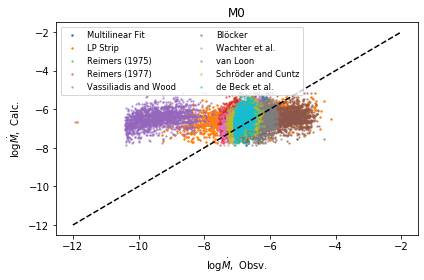


 ______________ 

fit_coeffs: [array([-5.82424701,  0.13410214]), array([-6.28017897,  0.13410214]), array([-5.45407014,  0.11130462]), array([-5.42451258,  0.20770371]), array([-5.90172464,  0.13987576]), array([-6.11316505,  0.5041434 ])] [array([-5.17376611,  0.19947687]), array([-8.07548473e-14,  1.00000000e+00]), array([-0.31459516,  1.00000481])]
y_lists: [array([-7.43347268, -6.09245129]), array([-7.88940464, -6.54838325]), array([-6.78972561, -5.67667938]), array([-7.91695711, -5.83992   ]), array([-7.58023372, -6.18147615]), array([-12.16288583,  -7.12145184])] [array([-7.56748859, -5.57271986]), array([-12.,  -2.]), array([-12.31465291,  -2.31460479])]
Plot 1b


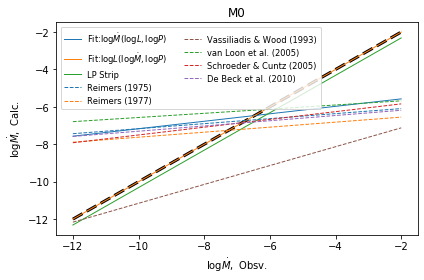

Dust-Fitting Results: (array([-5.17376611, -0.80052313]), 0.8005231263374807, Intercept    0.058191
x            0.008987
dtype: float64,            Intercept         x
Intercept   0.138389  0.021334
x           0.021334  0.003301)
Death Zone-Fitting Results: (array([-35.13037733,  -1.78904582]), 0.552603756620534, Intercept    0.234415
x            0.036204
dtype: float64,            Intercept         x
Intercept   0.138389  0.021334
x           0.021334  0.003301)
Reimers 1975 Results: (array([-5.82424701, -0.86589786]), 0.7970621583705233, Intercept    0.063625
x            0.009826
dtype: float64,            Intercept         x
Intercept   0.138389  0.021334
x           0.021334  0.003301)
Reimers 1977 Results: (array([-6.28017897, -0.86589786]), 0.7970621583705233, Intercept    0.063625
x            0.009826
dtype: float64,            Intercept         x
Intercept   0.138389  0.021334
x           0.021334  0.003301)
VW Results: (array([-6.11316505, -0.4958566 ]), 0.101692689642559

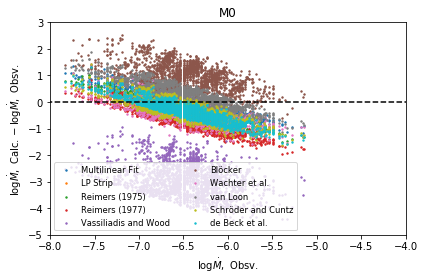


 ______________ 


 ______________ 



In [11]:
mdot_formula_comparison (M0StarData, spec_mode_label="M0",strip_type="LP")

For 4/21: 
1. Try and make these as a set of contour plots
-- Conclusion: Contour plots hide the problematic behavior of the linear fits and similar plots. The issues at the extremeties of these plots are not shown because stars are low density in those regions. In other words, we find most of them near the cliff so the linear fits are just capturing behavior near the cliff.
2. Create a subplot grid version of these plots with a single legend. 

In [12]:
def contour_plot(data_set, x_index=0, y_index=1, cmap_id=plt.cm.Greys,contour_ls = 'solid'):
    '''
    Creates a gaussian density contour plot using a row-wise data set "data_set".
    Options:
        x_index - specify which row of data to use as x-axis. Default is '0' (first row of data is x).
        y_index - specify which row of data to use as y-axis. Default is '1' (second row of data is y).
        cmap_id - specify which pyplot colormap to use. Default is "Greys" (greyscale colormap).
    '''
    x_data = data_set[x_index]
    y_data = data_set[y_index]
    x_data_min = np.nanmin(x_data)
    x_data_max = np.nanmax(x_data)
    y_data_min = np.nanmin(y_data)
    y_data_max = np.nanmax(y_data)
    contour_x, contour_y = np.mgrid[x_data_min:x_data_max:100j, y_data_min:y_data_max:100j]
    positions = np.vstack([contour_x.ravel(), contour_y.ravel()])
    values = np.vstack([x_data, y_data])
    kernel = sp.stats.gaussian_kde(values)
    Z = np.reshape(kernel(positions).T, contour_x.shape)
    plt.contour(contour_x, contour_y, Z, cmap=cmap_id,linestyles=contour_ls)

In [13]:
def mdot_mean_adjust (star_data, coeff_0, coeff_1, coeff_2,strip_type=''):
    logMData = np.log10(star_data[MIndex])
    logLData = np.log10(star_data[LIndex])
    logPData = np.log10(star_data[PIndex])
    logMdotData = np.log10(star_data[MdotIndex])
    logMdotData_mean = np.nanmean(logMdotData)
    if strip_type == 'LP':
        logMdotFormula = coeff_0 + coeff_1*logLData + coeff_2*logPData
    elif strip_type == 'LM':
        logMdotFormula = coeff_0 + coeff_1*logLData + coeff_2*logMData
    logMdotFormula_mean = np.nanmean(logMdotFormula)
    mean_dif = logMdotData_mean - logMdotFormula_mean
    new_coeff_0 = coeff_0 + mean_dif
    
    return new_coeff_0

In [14]:
def mdot_formula_comparison_contour (star_data, spec_mode_label = '',marker_size=2, strip_type = "LM",save = False):
    logLData = np.log10(star_data[LIndex])
    logMData = np.log10(star_data[MIndex])
    logPData = np.log10(star_data[PIndex])
    logRData = np.log10(star_data[RIndex])
    logTData = np.log10(star_data[TeffCalcIndex])
    logMdotData = np.log10(star_data[MdotIndex])
    logMdotperMData = np.log10(star_data[MdotIndex]/star_data[MIndex])
    fit_primary = multilinear_fit_2var([logLData,logPData],logMdotData)
    # Returns logMdot = A + BlogL + ClogP
    fit_secondary = multilinear_fit_2var([logMdotData,logPData],logLData)
    # Returns logL = A + BlogMdot + ClogP
    
    LPCoeffs = fit_primary[0]
    MdotPCoeffs = fit_secondary[0]
    fit_log_mdot = LPCoeffs[0] + LPCoeffs[1]*logLData + LPCoeffs[2]*logPData
    attenuation_log_mdot = (logLData - MdotPCoeffs[0] - MdotPCoeffs[2]*logPData)/MdotPCoeffs[1]
    # log Mdot = A + BlogL + ClogP
    if spec_mode_label[0] == 'M':
        RLM = RLM_M
    elif spec_mode_label[0] == 'C':
        RLM = RLM_C
    else:
        print('Error. Invalid label.')
        #break
    if spec_mode_label == 'M0':
        PMR = PMR_M0
        if strip_type == "LM":
            dz_values = M0_optimal_exponents_LM
        elif strip_type == "LP":
            dz_values = M0_optimal_exponents_LP
        else:
            print('Error. No strip Type Specified.')
            #break
    elif spec_mode_label == 'M1':
        PMR = PMR_M1
        if strip_type == "LM":
            dz_values = M1_optimal_exponents_LM
        elif strip_type == "LP":
            dz_values = M1_optimal_exponents_LP
        else:
            print('Error. No strip Type Specified.')
            #break
    elif spec_mode_label == 'C0':
        PMR = PMR_C0
        if strip_type == "LM":
            dz_values = C0_optimal_exponents_LM
        elif strip_type == "LP":
            dz_values = C0_optimal_exponents_LP
        else:
            print('Error. No strip Type Specified.')
            #break
    elif spec_mode_label == 'C0x':
        PMR = PMR_C0
        if strip_type == "LM":
            dz_values = C0_optimal_exponents_LM
        elif strip_type == "LP":
            dz_values = C0_optimal_exponents_LP
        else:
            print('Error. No strip Type Specified.')
            #break
    elif spec_mode_label == 'C0 and C0x':
        PMR = PMR_C0
        if strip_type == "LM":
            dz_values = C0_optimal_exponents_LM
        elif strip_type == "LP":
            dz_values = C0_optimal_exponents_LP
        else:
            print('Error. No strip Type Specified.')
            #break
    elif spec_mode_label == 'C1':
        PMR = PMR_C1
        if strip_type == "LM":
            dz_values = C1_optimal_exponents_LM
        elif strip_type == "LP":
            dz_values = C1_optimal_exponents_LP
        else:
            print('Error. No strip Type Specified.')
            #break
    else:
        print('Error. Invalid label.')
        #break
    
    #artificial_data = make_artificial_set([star_data],0.2,grid_spacing = 75j)
    #artificial_logLData = artificial_data[0]
    #artificial_logMData = artificial_data[1]
    #artificial_logRData = RLM[0] + RLM[1]*artificial_logLData + RLM[2]*artificial_logMData
    #artificial_logPData = PMR[0] + PMR[1]*artificial_logMData + PMR[2]*artificial_logRData
    #artificial_logTData = np.log10(5778*np.sqrt(10**(artificial_logRData)/np.sqrt(10**artificial_logLData)))
        
    a = LPCoeffs[0]
    arlm = RLM[0]
    aRLM = arlm
    apmr = PMR[0]
    aPMR = apmr
    c = LPCoeffs[2]
    cpmr = PMR[2]
    cPMR = cpmr
    b = LPCoeffs[1]
    brlm = RLM[1]
    bRLM = brlm
    bpmr = PMR[1]
    bPMR = bpmr
    crlm = RLM[2]
    cRLM = crlm
    PMLCoeffs = calculate_PML_coeffs(RLM, PMR)
    aPML = PMLCoeffs[0]
    bPML = PMLCoeffs[1]
    cPML = PMLCoeffs[2]
    
    
    # Coefficients for the Mdot(L,P) fit as a function Mdot(L, P)
    aMdotLP = a
    bMdotLP   = b
    cMdotLP  = c
    
    Anew = a - arlm + apmr*c + arlm*c*cpmr
    Bnew = b - brlm + brlm*c*cpmr 
    Cnew = bpmr*c - crlm + c*cpmr*crlm
    print('log Mdot(logL, logP):')
    #print('LRM form: logMdot =',Anew,' + ',Bnew,'logL + logR -',-Cnew,'logM')
    print('LM form: logMdot =',Anew+arlm,' + ',Bnew+brlm,'logL -',-(Cnew+crlm),'logM')
    #####
    
    # Use artificial star data to create plots demonstrating how our formulas differ from eachother and other notable formulas 
    
    
    color_list = ['tab:blue','tab:orange','tab:green','tab:red','tab:purple','tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']
    
    LPmultilinear_fit = multilinear_fit_2var([logLData,logPData],logMdotData)
    LPCoeffs = LPmultilinear_fit[0]
    our_log_mdot = LPCoeffs[0] + LPCoeffs[1]*logLData + LPCoeffs[2]*logPData
    # log Mdot = A + BlogL + ClogP
    '''
    if spec_mode_label[0] == 'M':
        RLM = RLM_M
    if spec_mode_label[0] == 'C':
        RLM = RLM_C
    if spec_mode_label == 'M0':
        PMR = PMR_M0
        dz_values = deathzone_values_M0
    if spec_mode_label == 'M1':
        PMR = PMR_M1
        dz_values = deathzone_values_M1
    if spec_mode_label == 'C0':
        PMR = PMR_C0
        dz_values = deathzone_values_C0
    if spec_mode_label == 'C0x':
        PMR = PMR_C0
        dz_values = deathzone_values_C0x
    if spec_mode_label == 'C0 and C0x':
        PMR = PMR_C0
        dz_values = deathzone_values_C0_and_C0x
    if spec_mode_label == 'C1':
        PMR = PMR_C1
        dz_values = deathzone_values_C1
    if spec_mode_label == 'C0 and C0x':
        PMR = PMR_C0
        dz_values = deathzone_values_C0_and_C0x
    '''
    
    #artificial_data = make_artificial_set([star_data],0.2,grid_spacing = 75j)
    #artificial_logLData = artificial_data[0]
    #artificial_logMData = artificial_data[1]
    #artificial_logRData = RLM[0] + RLM[1]*artificial_logLData + RLM[2]*artificial_logMData
    #artificial_logPData = PMR[0] + PMR[1]*artificial_logMData + PMR[2]*artificial_logRData
    #artificial_logTData = np.log10(5778*np.sqrt(10**(artificial_logRData)/np.sqrt(10**artificial_logLData)))
        
    a = LPCoeffs[0]
    arlm = RLM[0]
    aRLM = arlm
    apmr = PMR[0]
    aPMR = apmr
    c = LPCoeffs[2]
    cpmr = PMR[2]
    cPMR = cpmr
    b = LPCoeffs[1]
    brlm = RLM[1]
    bRLM = brlm
    bpmr = PMR[1]
    bPMR = bpmr
    crlm = RLM[2]
    cRLM = crlm
    PMLCoeffs = calculate_PML_coeffs(RLM, PMR)
    aPML = PMLCoeffs[0]
    bPML = PMLCoeffs[1]
    cPML = PMLCoeffs[2]
    
    Anew = a - arlm + apmr*c + arlm*c*cpmr
    Bnew = b - brlm + brlm*c*cpmr 
    Cnew = bpmr*c - crlm + c*cpmr*crlm
    print('log Mdot ~ logL + logP:')
    print('LRM form: logMdot =',Anew,' + ',Bnew,'logL + logR -',-Cnew,'logM')
    print('LM form: logMdot =',Anew+arlm,' + ',Bnew+brlm,'logL -',-(Cnew+crlm),'logM')
    
    print('______________')
    
    if strip_type == "LM":
        print('log Mdot ~ logL + logM (LM Strip)')
        dz_values[0] = mdot_mean_adjust(star_data, dz_values[0], dz_values[1], dz_values[2],strip_type='LM')
        print('LM form: logMdot =',dz_values[0],' + ',dz_values[1],'logL -',np.abs(dz_values[2]),'logM')
    if strip_type == "LP":
        print('log Mdot ~ logL + logP (LP Strip)')
        dz_values[0] = mdot_mean_adjust(star_data, dz_values[0], dz_values[1], dz_values[2],strip_type='LP')
        print('LP form: logMdot =',dz_values[0],' + ',dz_values[1],'logL -',np.abs(dz_values[2]),'logP')
    
    print('______________')
    
    if strip_type == "LM":
        dz_log_mdot = dz_values[0] + dz_values[1]*logLData + dz_values[2]*logMData
    elif strip_type == "LP":
        dz_log_mdot = dz_values[0] + dz_values[1]*logLData + dz_values[2]*logPData
    
    Reimers_log_mdot = np.log10(4*10**-13) + logLData + logRData - logMData
    # Mdot = (4*10^-13) * eta * LR/M => logMdot = log(4*10^-13) + log(eta) + logL + logR - logM
    # 1975
    print('Reimers 1975 LRM form: logMdot =',np.log10(4*10**-13),'+ logL + logR - logM')
    Aprint = np.log10(4*10**-13) + aRLM
    Bprint = 1 + bRLM
    Cprint = -1 + cRLM
    print('Reimers 1975 LM form: logMdot =', Aprint,'+',Bprint,'logL - ',np.abs(Cprint),'logM')
    fit = linear_fit_1var(logMdotData,Reimers_log_mdot)
    print('Calc vs Obsv Slope:', fit[0][1])
    print('Calc vs Obsv R^2:',fit[1])
    print('SDev of Residual:',np.nanstd(Reimers_log_mdot-logMdotData))
    print('Mean distance from 1-to-1 line:',np.nanmean(np.abs(Reimers_log_mdot-logMdotData)))
    
    print('______________')
    
    Reimers_log_mdot_2 = Reimers_log_mdot +np.log10(0.35)
    # Mdot = (4*10^-13) * 0.35 * LR/M => logMdot = log(4*10^-13) + log(0.35) + logL + logR - logM
    # http://cdsads.u-strasbg.fr/pdf/1977A%26A....61..217R, 1977
    print('Reimers 1977 LRM form: logMdot =',np.log10(4*10**-13)+np.log10(0.35),'+ logL + logR - logM')
    Aprint = np.log10(4*10**-13)+np.log10(0.35) + aRLM
    Bprint = 1 + bRLM
    Cprint = -1 + cRLM
    print('Reimers 1977 LM form: logMdot =', Aprint,'+',Bprint,'logL - ',np.abs(Cprint),'logM')
    fit = linear_fit_1var(logMdotData,Reimers_log_mdot_2)
    print('Calc vs Obsv Slope:', fit[0][1])
    print('Calc vs Obsv R^2:',fit[1])
    print('SDev of Residual:',np.nanstd(Reimers_log_mdot_2-logMdotData))
    print('Mean distance from 1-to-1 line:',np.nanmean(np.abs(Reimers_log_mdot_2-logMdotData)))
    
    print('______________')
    
    VW_log_mdot = calc_vw_mdot(logPData, logMData)
    # log Mdot = -11.4 + 0.0125(P-100(M-2.5))
    # http://adsabs.harvard.edu/abs/1993ApJ...413..641V, 1993
    apprx_fit = multilinear_fit_2var([logLData,logMData],VW_log_mdot)
    apprx_fit_coeffs = apprx_fit[0]
    print('VW LRM form: N/A')
    if apprx_fit_coeffs[2]>0:
        print('VW LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','+',apprx_fit_coeffs[2],'logM')
    else:
        print('VW LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','-',np.abs(apprx_fit_coeffs[2]),'logM')
    fit = linear_fit_1var(logMdotData,VW_log_mdot)
    print('Calc vs Obsv Slope:', fit[0][1])
    print('Calc vs Obsv R^2:',fit[1])
    print('SDev of Residual:',np.nanstd(VW_log_mdot-logMdotData))
    print('Mean distance from 1-to-1 line:',np.nanmean(np.abs(VW_log_mdot-logMdotData)))

    print('______________')
    
    Bloecker_log_mdot = np.log10(1.932*10**-21) + 3.7*logLData + logRData - 3.1*logMData
    # Mdot = (4.83*10^-9) (M^-2.1)(L^2.7)(Mdot_R=(4*10^-13) * eta * LR/M) = (1.932*10^-21)(L^3.7)(R)(M^-3.1)
    # -> logMdot = log[1.932*10^-21] + 3.7logL + logR - 3.1logM
    # https://ui.adsabs.harvard.edu/abs/1995A&A...297..727B, 1995
    print('Bloecker LRM form: logMdot =',np.log10(1.932*10**-21),'+3.7logL + logR - 3.1logM')
    Aprint = np.log10(1.932*10**-21) + aRLM
    Bprint = 3.7 + bRLM
    Cprint = -3.1 + cRLM
    print('Bloecker LM form: logMdot =',Aprint,'+',Bprint,'logL - ',np.abs(Cprint), 'logM')
    fit = linear_fit_1var(logMdotData,Bloecker_log_mdot)
    print('Calc vs Obsv Slope:', fit[0][1])
    print('Calc vs Obsv R^2:',fit[1])
    print('SDev of Residual:',np.nanstd(Bloecker_log_mdot-logMdotData))
    print('Mean distance from 1-to-1 line:',np.nanmean(np.abs(Bloecker_log_mdot-logMdotData)))
    
    print('______________')
    
    Wachter_log_mdot = 9.84423 + 1.54*logLData - 1.95*logMData + 0.959*logPData - 6.8*logTData
    # logMdot = -4.52 - 6.81(logT/2600 K) + 1.54log(L/10^4 Lsun) - 1.95log(M/Msun)+0.959log(P/650d)
    # -> logMdot = 9.84423 + 1.54logL -1.95logM + 0.959logP - 6.8logT
    # https://ui.adsabs.harvard.edu/abs/2002A&A...384..452W, 2002
    # from definition of effective temp., logT = 0.940482 + 0.25logL - 0.5logR (in solar units and Tsun = 5780K)
    WachterA = -6.39528 + 9.84423 + 0.959*aPML + 2.4*aRLM
    WachterB = -1.7 + 1.54 + 0.959*bPML+2.4*bRLM
    WachterC = -1.95 + 0.959*cPML+2.4*cRLM
    if WachterC <0:
        print('Wachter LRM form: logMdot =',WachterA,' + ',WachterB,'logL - ',np.abs(WachterC),'logM + logR')
    else:
        print('Wachter LRM form: logMdot =',WachterA,' + ',WachterB,'logL + ',WachterC,'logM + logR')
    Aprint = WachterA + aRLM
    Bprint = WachterB + bRLM
    Cprint = WachterC + cRLM
    if Cprint < 0:
        print('Wachter LM form: logMdot =',Aprint,' + ',Bprint,'logL - ',np.abs(Cprint),'logM')
    else:
        print('Wachter LM form: logMdot =',Aprint,' + ',Bprint,'logL + ',Cprint,'logM')
    fit = linear_fit_1var(logMdotData,Wachter_log_mdot)
    print('Calc vs Obsv Slope:', fit[0][1])
    print('Calc vs Obsv R^2:',fit[1])
    print('SDev of Residual:',np.nanstd(Wachter_log_mdot-logMdotData))
    print('Mean distance from 1-to-1 line:',np.nanmean(np.abs(Wachter_log_mdot-logMdotData)))
    
    print('______________')
    
    van_Loon_log_mdot = 12.4776 + 1.05*logLData - 6.3*logTData
    # logMdot = -5.65 + 1.05 log(L/10000Lsun) - 6.3log(T/3500K)
    # -> logMdot = 12.4776 + 1.05logL - 6.3logT
    vanLoonA = -5.92504 + 12.4776 + 2.15*aRLM 
    vanLoonB = -1.575+1.05+2.15*bRLM
    vanLoonC = 2.15*cRLM
    if vanLoonC <0:
        print('van Loon LRM form: logMdot =',vanLoonA,' + ',vanLoonB,'logL -',np.abs(vanLoonC),'logM + logR')
    else:
        print('van Loon LRM form: logMdot =',vanLoonA,' + ',vanLoonB,'logL +',vanLoonC,'logM + logR')
    Aprint = vanLoonA + aRLM
    Bprint = vanLoonB + bRLM
    Cprint = vanLoonC + cRLM
    if Cprint <0:
        print('van Loon LM form: logMdot =',Aprint,' + ',Bprint,'logL -',np.abs(Cprint),'logM')
    else:
        print('van Loon LM form: logMdot =',Aprint,' + ',Bprint,'logL +',Cprint,'logM')
    fit = linear_fit_1var(logMdotData,van_Loon_log_mdot)
    print('Calc vs Obsv Slope:', fit[0][1])
    print('Calc vs Obsv R^2:',fit[1])
    print('SDev of Residual:',np.nanstd(van_Loon_log_mdot-logMdotData))
    print('Mean distance from 1-to-1 line:',np.nanmean(np.abs(van_Loon_log_mdot-logMdotData)))
    
    print('______________')
    
    g = 10**logMData/(10**logRData)**2
    Schroeder_Cuntz_log_mdot = np.log10(0.2*10**Reimers_log_mdot*(10**logTData/4000)**3.5*(1+1/(4300*g)))
    # Mdot = (Mdot_R=(4*10^-13) * eta * LR/M)(T/4000 K)^3.5 (1 + g_sun/4300g_star)
    # http://adsabs.harvard.edu/abs/2005ApJ...630L..73S, 2005
    apprx_fit = multilinear_fit_2var([logLData,logMData],Schroeder_Cuntz_log_mdot)
    apprx_fit_coeffs = apprx_fit[0]
    print('Schroeder and Cuntz LRM form: N/A')
    if apprx_fit_coeffs[2]>0:
        print('Schroeder and Cuntz LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','+',apprx_fit_coeffs[2],'logM')
    else:
        print('Schroeder and Cuntz LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','-',np.abs(apprx_fit_coeffs[2]),'logM')
    
    fit = linear_fit_1var(logMdotData,Schroeder_Cuntz_log_mdot)
    print('Calc vs Obsv Slope:', fit[0][1])
    print('Calc vs Obsv R^2:',fit[1])
    print('SDev of Residual:',np.nanstd(Schroeder_Cuntz_log_mdot-logMdotData))
    print('Mean distance from 1-to-1 line:',np.nanmean(np.abs(Schroeder_Cuntz_log_mdot-logMdotData)))
    print('______________')
    
    de_Beck_log_mdot = calc_de_beck_mdot(logPData)
    # log Mdot = -7.37 + 3.42*10^-3 * P (P<850)
    #          = -4.46                  (P>850)
    # https://ui.adsabs.harvard.edu/abs/2010A&A...523A..18D, 2010
    apprx_fit = multilinear_fit_2var([logLData,logMData],de_Beck_log_mdot)
    apprx_fit_coeffs = apprx_fit[0]
    print('de Beck LRM form: N/A')
    if apprx_fit_coeffs[2]>0:
        print('de Beck LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','+',apprx_fit_coeffs[2],'logM')
    else:
        print('de Beck LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','-',np.abs(apprx_fit_coeffs[2]),'logM')
    
    fit = linear_fit_1var(logMdotData,de_Beck_log_mdot)
    print('Calc vs Obsv Slope:', fit[0][1])
    print('Calc vs Obsv R^2:',fit[1])
    print('SDev of Residual:',np.nanstd(de_Beck_log_mdot-logMdotData))
    print('Mean distance from 1-to-1 line:',np.nanmean(np.abs(de_Beck_log_mdot-logMdotData)))
    print('______________')
    
    obsv_data_range = np.asarray([-9.5,-3.5])
    
    others_lw = 3
    others_alpha = 0.5
    
    # Type 1b: Linear Fits for Obsv. vs. Calc., selected formulae only!
    # We've narrowed down which formulae we want to compare to, so only those are included in these plots.
    plot.plot([-12,-2],[-12,-2],color = 'black', alpha = 1,linestyle='--',linewidth=3)
    #plot.xlim(-8,-4)
    #plot.ylim(-8,-4)
    
    plot.title(spec_mode_label)
    plot.ylabel(r'$\log \dot{M},\ \mathrm{Calc.}$')
    plot.xlabel(r'$\log \dot{M},\ \mathrm{Obsv.}$')
    #plot.tight_layout()
    
    MdotLP_log_mdot = fit_log_mdot
    LMdotP_log_mdot = attenuation_log_mdot
    LMStrip_log_mdot = dz_log_mdot
    
    logMdot_results_list = [MdotLP_log_mdot, LMdotP_log_mdot,LMStrip_log_mdot]
    
    logMdot_formulae_list = [Reimers_log_mdot, Reimers_log_mdot_2, van_Loon_log_mdot, 
                             Schroeder_Cuntz_log_mdot, de_Beck_log_mdot,VW_log_mdot]
    
    cmap_list = [plt.cm.Blues,plt.cm.Oranges, plt.cm.Greens, plt.cm.Reds, plt.cm.Purples]
    color_list = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']
    for i in range(0, len(logMdot_results_list)):
        print(i,':',logMdot_results_list[i])
        contour_plot([logMdotData, logMdot_results_list[i]],cmap_id = cmap_list[i])
        plot.scatter(logMdotData, logMdot_results_list[i],color=color_list[i],s=2,alpha=0.3)
    our_forms_ls = '-'
    '''
    plot.plot(x_list,y_lists_results[0],color = color_list[0], linewidth = 1,linestyle=our_forms_ls, label='Fit:'+r'$\log \dot{M}(\log L, \log P)$')
    plot.plot(x_list,y_lists_results[1],color = color_list[1], linewidth = 1,linestyle=our_forms_ls, label='Fit:'+r'$\log L(\log \dot{M}, \log P)$')
    if strip_type == "LM":
        plot.plot(x_list,y_lists_results[2],color = color_list[2], linewidth = 1,linestyle=our_forms_ls, label='LM Strip')
    elif strip_type == "LP":
        plot.plot(x_list,y_lists_results[2],color = color_list[2], linewidth = 1,linestyle=our_forms_ls, label='LP Strip')
    '''
    other_form_ls = '--'
    '''
    plot.plot(x_list, y_lists[0],color = color_list[0], linewidth = 1,linestyle=other_form_ls, label='Reimers (1975)')
    plot.plot(x_list, y_lists[1],color = color_list[1], linewidth = 1,linestyle=other_form_ls, label='Reimers (1977)')
    if spec_mode_label == 'M0' or spec_mode_label == 'C0' or spec_mode_label == 'C0x' or spec_mode_label == 'C0 and C0x':
        plot.plot(x_list, y_lists[5],color = color_list[5], linewidth = 1,linestyle=other_form_ls, label='Vassiliadis & Wood (1993)')
    if spec_mode_label == 'M0' or spec_mode_label == 'M1' or spec_mode_label == 'M0 and M1':
        plot.plot(x_list, y_lists[2],color = color_list[2], linewidth = 1,linestyle=other_form_ls, label='van Loon et al. (2005)')
    plot.plot(x_list, y_lists[3],color = color_list[3], linewidth = 1,linestyle=other_form_ls, label='Schroeder & Cuntz (2005)')
    plot.plot(x_list, y_lists[4],color = color_list[4], linewidth = 1,linestyle=other_form_ls, label='De Beck et al. (2010)')
    '''
    #plot.legend(fontsize='small',ncol=2,loc=2)
    if save == True:
        plot.savefig('Final_Fit/Form_Comparison_1b_'+spec_mode_label+'.png')
        plot.savefig('Final_Fit/Form_Comparison_1b_'+spec_mode_label+'.pdf')
    print('Plot 1b')
    plot.xlim(-9,-4)
    plot.ylim(-9,-4)
    plot.show()
    plot.close()


log Mdot(logL, logP):
LM form: logMdot = -12.764064141313392  +  1.7956380283723272 logL - 2.586446105952449 logM
log Mdot ~ logL + logP:
LRM form: logMdot = -12.523064141313393  +  1.1056380283723273 logL + logR - 2.335446105952449 logM
LM form: logMdot = -12.764064141313392  +  1.7956380283723272 logL - 2.586446105952449 logM
______________
log Mdot ~ logL + logP (LP Strip)
LP form: logMdot = -6.313628905921609  +  -6.672284306164037 logL - 10.658943164562999 logP
______________
Reimers 1975 LRM form: logMdot = -12.397940008672037 + logL + logR - logM
Reimers 1975 LM form: logMdot = -12.638940008672037 + 1.69 logL -  1.251 logM
Calc vs Obsv Slope: 0.1341021390793589
Calc vs Obsv R^2: 0.08609325242342991
SDev of Residual: 0.37946776636899787
Mean distance from 1-to-1 line: 0.35225651520482393
______________
Reimers 1977 LRM form: logMdot = -12.853871964321762 + logL + logR - logM
Reimers 1977 LM form: logMdot = -13.094871964321761 + 1.69 logL -  1.251 logM
Calc vs Obsv Slope: 0.134102

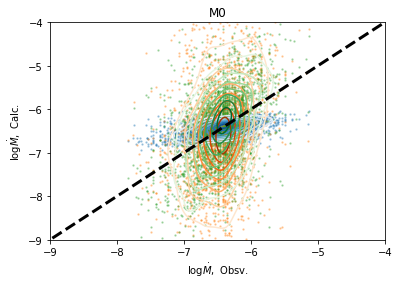

In [15]:
mdot_formula_comparison_contour (M0StarData, spec_mode_label="M0",strip_type="LP")

In [53]:
def mdot_formula_comparison_subplots(star_data_list_list, spec_mode_label_array,marker_size=2, strip_type = "LM",save = False):
    fig, axs = plt.subplots(2,2)
    
    for i in range(0,len(star_data_list_list)):
        for k in range(0, len(star_data_list_list[i])):
            star_data = star_data_list_list[i][k]
            spec_mode_label = spec_mode_label_array[i][k]
            print('-----\n',spec_mode_label,'\n-----')
            if len(spec_mode_label) < 3:
                text_x = 0.05
            else:
                text_x = 0.12
            logMData = np.log10(star_data[MIndex])
            logLData = np.log10(star_data[LIndex])
            logPData = np.log10(star_data[PIndex])
            logMdotData = np.log10(star_data[MdotIndex])
            logMdotperMData = np.log10(star_data[MdotIndex]/star_data[MIndex])
            fit_primary = multilinear_fit_2var([logLData,logPData],logMdotData)
            # Returns logMdot = A + BlogL + ClogP
            fit_secondary = multilinear_fit_2var([logMdotData,logPData],logLData)
            # Returns logL = A + BlogMdot + ClogP

            LPCoeffs = fit_primary[0]
            MdotPCoeffs = fit_secondary[0]
            fit_log_mdot = LPCoeffs[0] + LPCoeffs[1]*logLData + LPCoeffs[2]*logPData
            attenuation_log_mdot = (logLData - MdotPCoeffs[0] - MdotPCoeffs[2]*logPData)/MdotPCoeffs[1]
            # log Mdot = A + BlogL + ClogP
            if spec_mode_label[0] == 'M':
                RLM = RLM_M
            elif spec_mode_label[0] == 'C':
                RLM = RLM_C
            else:
                print('Error. Invalid label.')
                #break
            if spec_mode_label == 'M0':
                PMR = PMR_M0
                if strip_type == "LM":
                    dz_values = M0_optimal_exponents_LM
                elif strip_type == "LP":
                    dz_values = M0_optimal_exponents_LP
                else:
                    print('Error. No strip Type Specified.')
                    #break
            elif spec_mode_label == 'M1':
                PMR = PMR_M1
                if strip_type == "LM":
                    dz_values = M1_optimal_exponents_LM
                elif strip_type == "LP":
                    dz_values = M1_optimal_exponents_LP
                else:
                    print('Error. No strip Type Specified.')
                    #break
            elif spec_mode_label == 'C0':
                PMR = PMR_C0
                if strip_type == "LM":
                    dz_values = C0_optimal_exponents_LM
                elif strip_type == "LP":
                    dz_values = C0_optimal_exponents_LP
                else:
                    print('Error. No strip Type Specified.')
                    #break
            elif spec_mode_label == 'C0x':
                PMR = PMR_C0
                if strip_type == "LM":
                    dz_values = C0_optimal_exponents_LM
                elif strip_type == "LP":
                    dz_values = C0_optimal_exponents_LP
                else:
                    print('Error. No strip Type Specified.')
                    #break
            elif spec_mode_label == 'C0 and C0x':
                PMR = PMR_C0
                if strip_type == "LM":
                    dz_values = C0_optimal_exponents_LM
                elif strip_type == "LP":
                    dz_values = C0_optimal_exponents_LP
                else:
                    print('Error. No strip Type Specified.')
                    #break
            elif spec_mode_label == 'C1':
                PMR = PMR_C1
                if strip_type == "LM":
                    dz_values = C1_optimal_exponents_LM
                elif strip_type == "LP":
                    dz_values = C1_optimal_exponents_LP
                else:
                    print('Error. No strip Type Specified.')
                    #break
            else:
                print('Error. Invalid label.')
                #break

            a = LPCoeffs[0]
            arlm = RLM[0]
            aRLM = arlm
            apmr = PMR[0]
            aPMR = apmr
            c = LPCoeffs[2]
            cpmr = PMR[2]
            cPMR = cpmr
            b = LPCoeffs[1]
            brlm = RLM[1]
            bRLM = brlm
            bpmr = PMR[1]
            bPMR = bpmr
            crlm = RLM[2]
            cRLM = crlm
            PMLCoeffs = calculate_PML_coeffs(RLM, PMR)
            aPML = PMLCoeffs[0]
            bPML = PMLCoeffs[1]
            cPML = PMLCoeffs[2]


            # Coefficients for the Mdot(L,P) fit as a function Mdot(L, P)
            aMdotLP = a
            bMdotLP   = b
            cMdotLP  = c

            Anew = a - arlm + apmr*c + arlm*c*cpmr
            Bnew = b - brlm + brlm*c*cpmr 
            Cnew = bpmr*c - crlm + c*cpmr*crlm
            print('log Mdot(logL, logP):')
            #print('LRM form: logMdot =',Anew,' + ',Bnew,'logL + logR -',-Cnew,'logM')
            print('LM form: logMdot =',Anew+arlm,' + ',Bnew+brlm,'logL -',-(Cnew+crlm),'logM')
            #####

            # Use artificial star data to create plots demonstrating how our formulas differ from eachother and other notable formulas 
            logLData = np.log10(star_data[LIndex])
            logMData = np.log10(star_data[MIndex])
            logPData = np.log10(star_data[PIndex])
            logRData = np.log10(star_data[RIndex])
            logTData = np.log10(star_data[TeffCalcIndex])
            logMdotData = np.log10(star_data[MdotIndex])


            color_list = ['tab:green','tab:blue','tab:orange','tab:red','tab:purple','tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']

            LPmultilinear_fit = multilinear_fit_2var([logLData,logPData],logMdotData)
            LPCoeffs = LPmultilinear_fit[0]
            our_log_mdot = LPCoeffs[0] + LPCoeffs[1]*logLData + LPCoeffs[2]*logPData

            a = LPCoeffs[0]
            arlm = RLM[0]
            aRLM = arlm
            apmr = PMR[0]
            aPMR = apmr
            c = LPCoeffs[2]
            cpmr = PMR[2]
            cPMR = cpmr
            b = LPCoeffs[1]
            brlm = RLM[1]
            bRLM = brlm
            bpmr = PMR[1]
            bPMR = bpmr
            crlm = RLM[2]
            cRLM = crlm
            PMLCoeffs = calculate_PML_coeffs(RLM, PMR)
            aPML = PMLCoeffs[0]
            bPML = PMLCoeffs[1]
            cPML = PMLCoeffs[2]

            Anew = a - arlm + apmr*c + arlm*c*cpmr
            Bnew = b - brlm + brlm*c*cpmr 
            Cnew = bpmr*c - crlm + c*cpmr*crlm
            print('log Mdot ~ logL + logP:')
            print('LRM form: logMdot =',Anew,' + ',Bnew,'logL + logR -',-Cnew,'logM')
            print('LM form: logMdot =',Anew+arlm,' + ',Bnew+brlm,'logL -',-(Cnew+crlm),'logM')

            print('______________')

            if strip_type == "LM":
                print('log Mdot ~ logL + logM (LM Strip)')
                dz_values[0] = mdot_mean_adjust(star_data, dz_values[0], dz_values[1], dz_values[2],strip_type='LM')
                print('LM form: logMdot =',dz_values[0],' + ',dz_values[1],'logL -',np.abs(dz_values[2]),'logM')
                dz_log_mdot = dz_values[0] + dz_values[1]*logLData + dz_values[2]*logMData
            if strip_type == "LP":
                print('log Mdot ~ logL + logP (LP Strip)')
                dz_values[0] = mdot_mean_adjust(star_data, dz_values[0], dz_values[1], dz_values[2],strip_type='LP')
                print('LP form: logMdot =',dz_values[0],' + ',dz_values[1],'logL -',np.abs(dz_values[2]),'logP')
                dz_log_mdot = dz_values[0] + dz_values[1]*logLData + dz_values[2]*logPData
                if spec_mode_label == 'M0':
                    logAPMR = -2.234
                    BPMR = -0.7802
                    CPMR = 2.027
                    logARLM = -0.241
                    BRLM = 0.690
                    CRLM = -0.251
                logALP = dz_values[0]
                BLP = dz_values[1]
                CLP = dz_values[2]
                logA_LM = logALP + CLP*aPMR + CLP*cPMR*aRLM
                B_LM = BLP+bRLM*CLP*cPMR
                C_LM = bPMR*CLP+CLP*cPMR*cRLM
                dz_values_transformed = [logA_LM, B_LM, C_LM]
                print('LM form (equivalent): logMdot =',dz_values_transformed[0],' + ',dz_values_transformed[1],'logL -',np.abs(dz_values_transformed[2]),'logM')

            print('______________')


            Reimers_log_mdot = np.log10(4*10**-13) + logLData + logRData - logMData
            # Mdot = (4*10^-13) * eta * LR/M => logMdot = log(4*10^-13) + log(eta) + logL + logR - logM
            # 1975
            print('Reimers 1975 LRM form: logMdot =',np.log10(4*10**-13),'+ logL + logR - logM')
            Aprint = np.log10(4*10**-13) + aRLM
            Bprint = 1 + bRLM
            Cprint = -1 + cRLM
            print('Reimers 1975 LM form: logMdot =', Aprint,'+',Bprint,'logL - ',np.abs(Cprint),'logM')
            fit = linear_fit_1var(logMdotData,Reimers_log_mdot)
            print('Calc vs Obsv Slope:', fit[0][1])
            print('Calc vs Obsv R^2:',fit[1])
            print('SDev of Residual:',np.nanstd(Reimers_log_mdot-logMdotData))
            print('Mean distance from 1-to-1 line:',np.nanmean(np.abs(Reimers_log_mdot-logMdotData)))

            print('______________')

            Reimers_log_mdot_2 = Reimers_log_mdot +np.log10(0.35)
            # Mdot = (4*10^-13) * 0.35 * LR/M => logMdot = log(4*10^-13) + log(0.35) + logL + logR - logM
            # http://cdsads.u-strasbg.fr/pdf/1977A%26A....61..217R, 1977
            print('Reimers 1977 LRM form: logMdot =',np.log10(4*10**-13)+np.log10(0.35),'+ logL + logR - logM')
            Aprint = np.log10(4*10**-13)+np.log10(0.35) + aRLM
            Bprint = 1 + bRLM
            Cprint = -1 + cRLM
            print('Reimers 1977 LM form: logMdot =', Aprint,'+',Bprint,'logL - ',np.abs(Cprint),'logM')
            fit = linear_fit_1var(logMdotData,Reimers_log_mdot_2)
            print('Calc vs Obsv Slope:', fit[0][1])
            print('Calc vs Obsv R^2:',fit[1])
            print('SDev of Residual:',np.nanstd(Reimers_log_mdot_2-logMdotData))
            print('Mean distance from 1-to-1 line:',np.nanmean(np.abs(Reimers_log_mdot_2-logMdotData)))

            print('______________')

            VW_log_mdot = calc_vw_mdot(logPData, logMData)
            # log Mdot = -11.4 + 0.0125(P-100(M-2.5))
            # http://adsabs.harvard.edu/abs/1993ApJ...413..641V, 1993
            apprx_fit = multilinear_fit_2var([logLData,logMData],VW_log_mdot)
            apprx_fit_coeffs = apprx_fit[0]
            print('VW LRM form: N/A')
            if apprx_fit_coeffs[2]>0:
                print('VW LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','+',apprx_fit_coeffs[2],'logM')
            else:
                print('VW LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','-',np.abs(apprx_fit_coeffs[2]),'logM')
            fit = linear_fit_1var(logMdotData,VW_log_mdot)
            print('Calc vs Obsv Slope:', fit[0][1])
            print('Calc vs Obsv R^2:',fit[1])
            print('SDev of Residual:',np.nanstd(VW_log_mdot-logMdotData))
            print('Mean distance from 1-to-1 line:',np.nanmean(np.abs(VW_log_mdot-logMdotData)))

            print('______________')

            Bloecker_log_mdot = np.log10(1.932*10**-21) + 3.7*logLData + logRData - 3.1*logMData
            # Mdot = (4.83*10^-9) (M^-2.1)(L^2.7)(Mdot_R=(4*10^-13) * eta * LR/M) = (1.932*10^-21)(L^3.7)(R)(M^-3.1)
            # -> logMdot = log[1.932*10^-21] + 3.7logL + logR - 3.1logM
            # https://ui.adsabs.harvard.edu/abs/1995A&A...297..727B, 1995
            print('Bloecker LRM form: logMdot =',np.log10(1.932*10**-21),'+3.7logL + logR - 3.1logM')
            Aprint = np.log10(1.932*10**-21) + aRLM
            Bprint = 3.7 + bRLM
            Cprint = -3.1 + cRLM
            print('Bloecker LM form: logMdot =',Aprint,'+',Bprint,'logL - ',np.abs(Cprint), 'logM')
            fit = linear_fit_1var(logMdotData,Bloecker_log_mdot)
            print('Calc vs Obsv Slope:', fit[0][1])
            print('Calc vs Obsv R^2:',fit[1])
            print('SDev of Residual:',np.nanstd(Bloecker_log_mdot-logMdotData))
            print('Mean distance from 1-to-1 line:',np.nanmean(np.abs(Bloecker_log_mdot-logMdotData)))
            
            print('______________')

            Wachter_log_mdot = 9.84423 + 1.54*logLData - 1.95*logMData + 0.959*logPData - 6.8*logTData
            # logMdot = -4.52 - 6.81(logT/2600 K) + 1.54log(L/10^4 Lsun) - 1.95log(M/Msun)+0.959log(P/650d)
            # -> logMdot = 9.84423 + 1.54logL -1.95logM + 0.959logP - 6.8logT
            # https://ui.adsabs.harvard.edu/abs/2002A&A...384..452W, 2002
            # from definition of effective temp., logT = 0.940482 + 0.25logL - 0.5logR (in solar units and Tsun = 5780K)
            WachterA = -6.39528 + 9.84423 + 0.959*aPML + 2.4*aRLM
            WachterB = -1.7 + 1.54 + 0.959*bPML+2.4*bRLM
            WachterC = -1.95 + 0.959*cPML+2.4*cRLM
            if WachterC <0:
                print('Wachter LRM form: logMdot =',WachterA,' + ',WachterB,'logL - ',np.abs(WachterC),'logM + logR')
            else:
                print('Wachter LRM form: logMdot =',WachterA,' + ',WachterB,'logL + ',WachterC,'logM + logR')
            Aprint = WachterA + aRLM
            Bprint = WachterB + bRLM
            Cprint = WachterC + cRLM
            if Cprint < 0:
                print('Wachter LM form: logMdot =',Aprint,' + ',Bprint,'logL - ',np.abs(Cprint),'logM')
            else:
                print('Wachter LM form: logMdot =',Aprint,' + ',Bprint,'logL + ',Cprint,'logM')
            fit = linear_fit_1var(logMdotData,Wachter_log_mdot)
            print('Calc vs Obsv Slope:', fit[0][1])
            print('Calc vs Obsv R^2:',fit[1])
            print('SDev of Residual:',np.nanstd(Wachter_log_mdot-logMdotData))
            print('Mean distance from 1-to-1 line:',np.nanmean(np.abs(Wachter_log_mdot-logMdotData)))

            print('______________')

            van_Loon_log_mdot = 12.4776 + 1.05*logLData - 6.3*logTData
            # logMdot = -5.65 + 1.05 log(L/10000Lsun) - 6.3log(T/3500K)
            # -> logMdot = 12.4776 + 1.05logL - 6.3logT
            vanLoonA = -5.92504 + 12.4776 + 2.15*aRLM 
            vanLoonB = -1.575+1.05+2.15*bRLM
            vanLoonC = 2.15*cRLM
            if vanLoonC <0:
                print('van Loon LRM form: logMdot =',vanLoonA,' + ',vanLoonB,'logL -',np.abs(vanLoonC),'logM + logR')
            else:
                print('van Loon LRM form: logMdot =',vanLoonA,' + ',vanLoonB,'logL +',vanLoonC,'logM + logR')
            Aprint = vanLoonA + aRLM
            Bprint = vanLoonB + bRLM
            Cprint = vanLoonC + cRLM
            if Cprint <0:
                print('van Loon LM form: logMdot =',Aprint,' + ',Bprint,'logL -',np.abs(Cprint),'logM')
            else:
                print('van Loon LM form: logMdot =',Aprint,' + ',Bprint,'logL +',Cprint,'logM')
            fit = linear_fit_1var(logMdotData,van_Loon_log_mdot)
            print('Calc vs Obsv Slope:', fit[0][1])
            print('Calc vs Obsv R^2:',fit[1])
            print('SDev of Residual:',np.nanstd(van_Loon_log_mdot-logMdotData))
            print('Mean distance from 1-to-1 line:',np.nanmean(np.abs(van_Loon_log_mdot-logMdotData)))

            print('______________')

            g = 10**logMData/(10**logRData)**2
            Schroeder_Cuntz_log_mdot = np.log10(0.2*10**Reimers_log_mdot*(10**logTData/4000)**3.5*(1+1/(4300*g)))
            # Mdot = (Mdot_R=(4*10^-13) * eta * LR/M)(T/4000 K)^3.5 (1 + g_sun/4300g_star)
            # http://adsabs.harvard.edu/abs/2005ApJ...630L..73S, 2005
            apprx_fit = multilinear_fit_2var([logLData,logMData],Schroeder_Cuntz_log_mdot)
            apprx_fit_coeffs = apprx_fit[0]
            print('Schroeder and Cuntz LRM form: N/A')
            if apprx_fit_coeffs[2]>0:
                print('Schroeder and Cuntz LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','+',apprx_fit_coeffs[2],'logM')
            else:
                print('Schroeder and Cuntz LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','-',np.abs(apprx_fit_coeffs[2]),'logM')

            fit = linear_fit_1var(logMdotData,Schroeder_Cuntz_log_mdot)
            print('Calc vs Obsv Slope:', fit[0][1])
            print('Calc vs Obsv R^2:',fit[1])
            print('SDev of Residual:',np.nanstd(Schroeder_Cuntz_log_mdot-logMdotData))
            print('Mean distance from 1-to-1 line:',np.nanmean(np.abs(Schroeder_Cuntz_log_mdot-logMdotData)))
            print('______________')

            de_Beck_log_mdot = calc_de_beck_mdot(logPData)
            # log Mdot = -11.4 + 0.0125(P-100(M-2.5))
            # log Mdot = -7.37 + 3.42*10^-3 * P (P<850) = -7.37 + 0.000342*P
            #          = -4.46                  (P>850)
            # https://ui.adsabs.harvard.edu/abs/2010A&A...523A..18D, 2010
            apprx_fit = multilinear_fit_2var([logLData,logMData],de_Beck_log_mdot)
            apprx_fit_coeffs = apprx_fit[0]
            print('de Beck LRM form: N/A')
            if apprx_fit_coeffs[2]>0:
                print('de Beck LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','+',apprx_fit_coeffs[2],'logM')
            else:
                print('de Beck LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','-',np.abs(apprx_fit_coeffs[2]),'logM')

            fit = linear_fit_1var(logMdotData,de_Beck_log_mdot)
            print('Calc vs Obsv Slope:', fit[0][1])
            print('Calc vs Obsv R^2:',fit[1])
            print('SDev of Residual:',np.nanstd(de_Beck_log_mdot-logMdotData))
            print('Mean distance from 1-to-1 line:',np.nanmean(np.abs(de_Beck_log_mdot-logMdotData)))
            print('______________')

            obsv_data_range = np.asarray([-9.5,-3.5])

            others_lw = 3
            others_alpha = 0.5
            
            # Type 1b: Linear Fits for Obsv. vs. Calc., selected formulae only!
            # We've narrowed down which formulae we want to compare to, so only those are included in these plots.
            #axs[i, k].plot([-12,-2],[-12,-2],color = 'black', alpha = 1,linestyle='--',linewidth=3)
            axs[i, k].set_xlim(-9,-4)
            axs[i, k].set_ylim(-9,-4)

            #axs[i, k].set_title(spec_mode_label)
            axs[i, k].text(text_x, .95,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = axs[i, k].transAxes,fontsize=10)
            if k == 0:
                axs[i, k].set_ylabel(r'$\log \dot{M},\ \mathrm{Calc.}$')
            if i == 1:
                axs[i, k].set_xlabel(r'$\log \dot{M},\ \mathrm{Obsv.}$')
            #axs[i, k].tight_layout()

            MdotLP_log_mdot = our_log_mdot
            LMdotP_log_mdot = attenuation_log_mdot
            LMStrip_log_mdot = dz_log_mdot

            logMdot_results_list = [MdotLP_log_mdot, LMdotP_log_mdot,LMStrip_log_mdot]

            logMdot_formulae_list = [Reimers_log_mdot, Reimers_log_mdot_2, van_Loon_log_mdot, 
                                     Schroeder_Cuntz_log_mdot, de_Beck_log_mdot,VW_log_mdot, Bloecker_log_mdot]
            fit_coeffs = []
            fit_coeffs_results = []
            for i2 in range(0, len(logMdot_formulae_list)): # Loops to do a bunch of linear fits and append the results to an array.
                # These same calculations were done above, but not saved sooooo...
                fit = linear_fit_1var(logMdotData, logMdot_formulae_list[i2])
                fit_coeffs.append(fit[0])
            for i3 in range(0, len(logMdot_results_list)): # Loops to do a bunch of linear fits and append the results to an array.
                # These same calculations were done above, but not saved sooooo...
                fit = linear_fit_1var(logMdotData, logMdot_results_list[i3])
                fit_coeffs_results.append(fit[0])
            print('fit_coeffs:',fit_coeffs, fit_coeffs_results)
            x_list = np.asarray([-12, -2])
            y_lists = []
            y_lists_results = []
            for i4 in range(0, len(logMdot_formulae_list)): # And now calculate y values...
                y_list = fit_coeffs[i4][0] + fit_coeffs[i4][1]*x_list
                y_lists.append(y_list)
            for i4 in range(0, len(logMdot_results_list)): # And now calculate y values...
                y_list = fit_coeffs_results[i4][0] + fit_coeffs_results[i4][1]*x_list
                y_lists_results.append(y_list)
            print('y_lists:',y_lists,y_lists_results)
            our_forms_ls = '-'
            if strip_type == "LM":
                axs[i, k].plot(x_list,y_lists_results[2],color = color_list[0], linewidth = 4,linestyle=our_forms_ls, label='LM Strip')
            elif strip_type == "LP":
                axs[i, k].plot(x_list,y_lists_results[2],color = color_list[0], linewidth = 4,linestyle=our_forms_ls, label='PL Strip')
            axs[i, k].plot(x_list,y_lists_results[0],color = color_list[1], linewidth = 1,linestyle=':', label='Fit:'+r'$\log \dot{M}(\log L, \log P)$')
            axs[i, k].plot(x_list,y_lists_results[1],color = 'k', linewidth = 1,linestyle=':', label='Fit:'+r'$\log L(\log \dot{M}, \log P)$')
            
            other_form_ls = '--'
            axs[i, k].plot(x_list, y_lists[0],color = color_list[0], linewidth = 1,linestyle=other_form_ls, label='Reimers (1975)')
            axs[i, k].plot(x_list, y_lists[1],color = color_list[1], linewidth = 1,linestyle=other_form_ls, label='Reimers (1977)')
            if spec_mode_label == 'M0' or spec_mode_label == 'M1' or spec_mode_label == 'M0 and M1':
                axs[i, k].plot(x_list, y_lists[2],color = color_list[2], linewidth = 1,linestyle=other_form_ls, label='van Loon et al. (2005)')
            axs[i, k].plot(x_list, y_lists[3],color = color_list[3], linewidth = 1,linestyle=other_form_ls, label=u'Schr\u00F6'+ 'der & Cuntz (2005)')
            axs[i, k].plot(x_list, y_lists[4],color = color_list[4], linewidth = 1,linestyle=other_form_ls, label='De Beck et al. (2010)')
            if spec_mode_label == 'M0' or spec_mode_label == 'C0' or spec_mode_label == 'C0x' or spec_mode_label == 'C0 and C0x':
                axs[i, k].plot(x_list, y_lists[5],color = color_list[5], linewidth = 1,linestyle=other_form_ls, label='Vassiliadis & Wood (1993)')
            axs[i, k].plot(x_list, y_lists[6],color = color_list[6], linewidth = 1,linestyle=other_form_ls, label='Bl'+u'\u00F6'+'cker (1995)')
            #plot.legend(fontsize='small',ncol=2,loc=2)
    
    handles, labels  = plt.gca().get_legend_handles_labels()
    lines_1 = []
    lines_2 = []
    label_list = []
    color_list_2 = ['tab:green', 'tab:blue', 'k']
    lines_1.append(plt.Line2D([0],[0],color = color_list_2[0], linewidth = 2, linestyle='-'))
    for i in range (1,len(logMdot_results_list)):
        lines_1.append(plt.Line2D([0],[0],color = color_list_2[i], linewidth = 2, linestyle=':'))
    for i in range (0,len(logMdot_formulae_list)):
        lines_2.append(plt.Line2D([0],[0],color = color_list[i], linewidth = 2, linestyle='--'))
    lines = lines_1 + lines_2
    if strip_type == 'LM':
        label_list = ['LM Strip', 'Fit:'+r'$\log \dot{M}(\log L, \log P)$', 'Fit:'+r'$\log L(\log \dot{M}, \log P)$',
                     'Reimers (1975)', 'Reimers (1977)', 'van Loon et al. (2005)', r'$\mathrm{Schr\"{o}der\ &\ Cuntz\ (2005)}$',
                     'de Beck et al. (2010)', 'Vassiliadis & Wood (1993)', 'Bl'+u'\u00F6'+'cker (1995)']    
    
    if strip_type == 'LP':
        label_list = ['PL Strip', 'Fit:'+r'$\log \dot{M}(\log L, \log P)$', 'Fit:'+r'$\log L(\log \dot{M}, \log P)$',
                     'Reimers (1975)', 'Reimers (1977)', 'van Loon et al. (2005)', r'$\mathrm{Schr\"{o}der\ &\ Cuntz\ (2005)}$',
                     'de Beck et al. (2010)', 'Vassiliadis & Wood (1993)', 'Bl'+u'\u00F6'+'cker (1995)']    
    plot.legend(lines, label_list, loc=8, bbox_to_anchor=(-0.1,-0.5),ncol=5)
    bottom_offset = 1
    fig.set_size_inches(11,8 )
    if save == True:
        fig.savefig('Final_Fit/Form_Comparison_combined'+'.png',pad_inches=0.05,bbox_inches = 'tight')
        fig.savefig('Final_Fit/Form_Comparison_combined'+'.pdf',pad_inches=0.05,bbox_inches = 'tight')
    plot.show()
    plot.close()


-----
 M0 
-----
log Mdot(logL, logP):
LM form: logMdot = -12.764064141313392  +  1.7956380283723272 logL - 2.586446105952449 logM
log Mdot ~ logL + logP:
LRM form: logMdot = -12.523064141313393  +  1.1056380283723273 logL + logR - 2.335446105952449 logM
LM form: logMdot = -12.764064141313392  +  1.7956380283723272 logL - 2.586446105952449 logM
______________
log Mdot ~ logL + logP (LP Strip)
LP form: logMdot = -6.313628905921608  +  -6.672284306164037 logL - 10.658943164562999 logP
LM form (equivalent): logMdot = -35.33267628404653  +  8.23563337208871 logL - 13.73913258342892 logM
______________
Reimers 1975 LRM form: logMdot = -12.397940008672037 + logL + logR - logM
Reimers 1975 LM form: logMdot = -12.638940008672037 + 1.69 logL -  1.251 logM
Calc vs Obsv Slope: 0.1341021390793589
Calc vs Obsv R^2: 0.08609325242342991
SDev of Residual: 0.37946776636899787
Mean distance from 1-to-1 line: 0.35225651520482393
______________
Reimers 1977 LRM form: logMdot = -12.853871964321762 + logL +

fit_coeffs: [array([-5.49037113,  0.13260874]), array([-5.94630308,  0.13260874]), array([-4.78299296,  0.1266974 ]), array([-4.94434477,  0.21293814]), array([-3.8306524 ,  0.36890294]), array([1.26099176, 1.31778412]), array([-2.57036704,  0.33743251])] [array([-3.72673172,  0.42060208]), array([-2.31759056e-13,  1.00000000e+00]), array([-0.00134994,  0.99979012])]
y_lists: [array([-7.08167603, -5.75558861]), array([-7.53760798, -6.21152057]), array([-6.30336174, -5.03638775]), array([-7.49960249, -5.37022106]), array([-8.25748762, -4.56845827]), array([-14.55241768,  -1.37457648]), array([-6.61955722, -3.24523207])] [array([-8.77395667, -4.56793588]), array([-12.,  -2.]), array([-11.99883142,  -2.00093019])]
-----
 C1 
-----
log Mdot(logL, logP):
LM form: logMdot = -14.774338489413376  +  2.2099236751177256 logL - 2.3380226554375767 logM
log Mdot ~ logL + logP:
LRM form: logMdot = -14.451338489413375  +  1.4729236751177255 logL + logR - 1.9670226554375767 logM
LM form: logMdot = -14

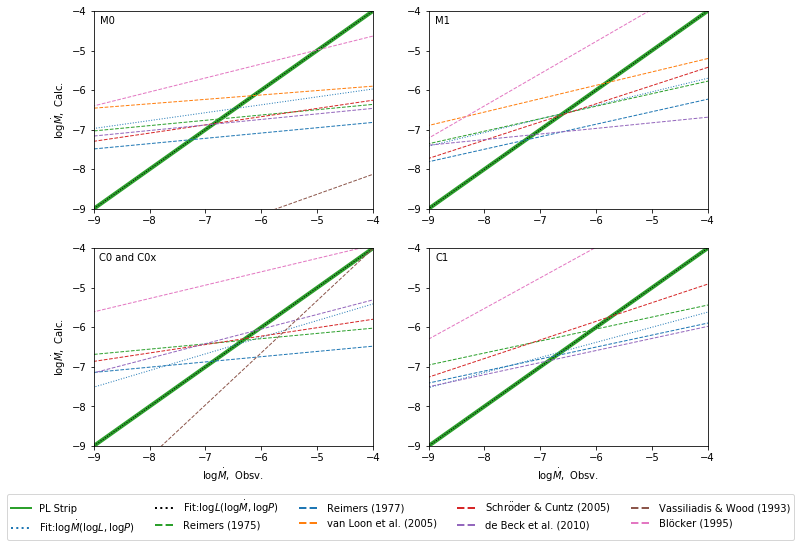

In [54]:
data_array=[[M0StarData, M1StarData],[C0StarData, C1StarData]]
label_array = np.asarray([['M0', 'M1'], ['C0 and C0x', 'C1']])
mdot_formula_comparison_subplots (data_array,label_array,strip_type='LP',save=True)